# Indian Stock Market — Evidence-Based Investment Strategy Analysis

---

## Section 0 — Project Overview

### Goal

This notebook provides a rigorous, data-driven comparison of the major investment vehicles available to an Indian retail investor over a **10-year horizon**:

- **Equity indices**: Nifty 50 and Sensex — the two primary large-cap benchmarks.
- **Active mutual funds**: Popular large-cap, flexi-cap, and mid-cap direct-growth plans from leading AMCs (Axis, HDFC, SBI, Mirae, Parag Parikh, UTI).
- **Gold ETF**: A liquid, exchange-traded proxy for physical gold (GOLDBEES on NSE).
- **Government Securities (G-Sec)**: 10-year Indian G-Sec yield, sourced from FRED or proxied from the RBI repo rate series.
- **Factor ETFs**: Momentum (MOM100), Value (NV20BEES), Quality (QUAL30IETF), and Next50 (JUNIORBEES) ETFs listed on NSE.
- **S&P 500 (USD)**: Included as a global benchmark for comparison.

All analysis uses actual price and NAV data downloaded automatically from Yahoo Finance and the AMFI database.

---

### Theoretical Framework

#### 1. Fama-French 3-Factor Model (1993)

Fama and French (1993) demonstrated that cross-sectional variation in equity returns is explained not just by market beta (CAPM) but also by:
- **SMB** (Small Minus Big): the size premium — small-cap stocks outperform large-cap stocks on average.
- **HML** (High Minus Low): the value premium — high book-to-market (value) stocks outperform low book-to-market (growth) stocks.

$$r_i - r_f = \alpha + \beta_{mkt}(r_m - r_f) + \beta_{smb} * SMB + \beta_{hml} * HML + \epsilon$$

#### 2. Carhart 4-Factor Model (1997)

Carhart (1997) added a **momentum factor (MOM)** to account for the tendency of recent winners to keep winning. This is especially useful for evaluating mutual fund manager skill — a fund's alpha after controlling for all four factors is a cleaner measure of genuine skill.

#### 3. Jensen's Alpha (1968)

Michael Jensen (1968) introduced the concept of alpha as the intercept in the CAPM regression — the return a manager generates *above* what the market exposure alone would predict. Positive, statistically significant alpha is the gold standard for active management.

#### 4. Indian Market Literature

- **Mohanty (2002)**: Documents a significant size effect (SMB) on Indian stock returns using BSE data from 1996-2001. Small-cap stocks outperformed large-caps by ~3-5% per year.
- **Wahal and Yezdi (2018)**: Construct FF3 and FF4 factors for India using CMIE Prowess data. They find that **value (HML)** and **momentum (MOM)** premia are positive and statistically significant in India, while the size (SMB) premium is borderline. Their most important finding for active fund analysis: most Indian active equity funds do *not* generate statistically significant alpha after controlling for these factors.

---

### Key Research Questions

1. **Do Indian active equity funds beat the index after costs?**
   Evidence from factor regressions: is Jensen's alpha positive and significant for active MFs after accounting for market, size, value, and momentum exposure?

2. **How does gold and G-Secs compare on a risk-adjusted basis?**
   Sharpe ratio, Sortino ratio, max drawdown, and correlation with equity are examined.

3. **Do Fama-French factors (SMB/HML/MOM) have positive premia in India?**
   We construct factor proxies from NSE ETF prices and measure their cumulative performance and Sharpe ratios.

4. **Should a 10-year investor use SIP into an index ETF, active MF, gold, bonds, or a factor portfolio?**
   A Rs 10,000/month SIP simulation across all assets answers this practically.

---

### Data Sources

| Data | Source | Auto? |
|------|--------|-------|
| Nifty 50, Sensex, S&P 500 | Yahoo Finance via `yfinance` | Yes |
| NSE ETFs (GOLDBEES, MOM100, etc.) | Yahoo Finance via `yfinance` | Yes |
| Mutual Fund NAVs | AMFI via `mftool` | Yes |
| RBI Repo Rate | Hard-coded series from RBI press releases | Yes |
| India 10Y G-Sec Yield | FRED (IRLTLT01INM156N) via `pandas_datareader` | Yes (falls back to repo+150bps if FRED unavailable) |

---

### How to Run

1. Install dependencies: `pip install yfinance mftool pandas-datareader statsmodels scipy seaborn`
2. Run all cells top-to-bottom (`Kernel > Restart & Run All`)
3. Charts are saved to `../data/processed/` for later reference
4. The analysis is fully reproducible — no manual data entry required

> **Note**: Mutual fund NAV data via `mftool` requires an active internet connection and may be slow. Index/ETF data from Yahoo Finance is generally fast. If any individual download fails, the notebook handles it gracefully and continues with available data.

## Section 1 — Setup

Import all libraries and define global constants used throughout the analysis.

In [1]:
import sys, os

sys.path.insert(0, os.path.abspath(".."))

import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy.optimize import minimize

from src.data_loader import (
    EXPENSE_RATIOS,
    FACTOR_ETF_TICKERS,
    INDEX_TICKERS,
    MUTUAL_FUND_CODES,
    download_mutual_fund_navs,
    download_prices,
    get_india_10y_gsec,
    get_rbi_repo_rate_series,
    to_monthly_prices,
    to_monthly_returns,
)
from src.factors import build_factor_returns, factor_summary_table, run_factor_regression
from src.metrics import (
    annualised_volatility,
    cagr,
    calmar_ratio,
    drawdown_series,
    max_drawdown,
    rolling_cagr,
    rolling_sharpe,
    sharpe_ratio,
    simulate_sip,
    sortino_ratio,
    summary_table,
    value_at_risk,
)
from src.tax_utils import (
    build_cost_comparison_table,
    debt_after_tax_return,
    equity_after_tax_return,
    expense_ratio_drag,
    gold_after_tax_return,
)
from src.visualization import (
    plot_correlation_heatmap,
    plot_cumulative_returns,
    plot_drawdowns,
    plot_efficient_frontier,
    plot_expense_drag,
    plot_factor_alphas,
    plot_metrics_bar,
    plot_rolling_cagr,
    plot_sip_growth,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="tab10")

# ── Global constants ───────────────────────────────────────────────────────────
START_DATE = "2005-01-01"
MONTHLY_SIP = 10_000  # Rs 10,000/month SIP
LUMP_SUM = 100_000  # Rs 1 lakh lump-sum baseline
RF_ANNUAL = 0.065  # 6.5% risk-free proxy (RBI repo rate, recent average)
HOLDING_YEARS = 10

# Ensure processed data directory exists
os.makedirs("../data/processed", exist_ok=True)

print("Libraries loaded successfully.")
print(f"Analysis start date : {START_DATE}")
print(f"Monthly SIP amount  : Rs {MONTHLY_SIP:,}")
print(f"Risk-free rate (ann): {RF_ANNUAL * 100:.1f}%")

Libraries loaded successfully.
Analysis start date : 2005-01-01
Monthly SIP amount  : Rs 10,000
Risk-free rate (ann): 6.5%


## Section 2 — Data Loading

### What we download and why

We gather data from three sources:

1. **Yahoo Finance** (`yfinance`): Adjusted close prices for major indices (Nifty 50, Sensex, S&P 500) and NSE-listed ETFs (GOLDBEES, MOM100, JUNIORBEES, NV20BEES, QUAL30IETF). Adjusted prices account for splits and dividends, making them suitable for long-horizon return calculations.

2. **AMFI via mftool**: Daily NAVs for actively managed and passively managed mutual funds. We use scheme codes from AMFI's official database. NAVs are already adjusted for distributions.

3. **RBI / FRED**: The RBI repo rate series is compiled from official press releases and used as the risk-free rate. The India 10-year G-Sec yield is fetched from FRED (Federal Reserve database) or proxied if FRED is unavailable.

All series are ultimately resampled to **month-end** prices and aligned on a common date grid for consistent analysis.

In [2]:
print("=" * 60)
print("=== Downloading Index Prices ===")
print("=" * 60)
index_prices = download_prices(INDEX_TICKERS, start=START_DATE)
print(f"\nDownloaded {len(index_prices)} index series.")

=== Downloading Index Prices ===
  [OK]   Nifty 50  (4682 days, 2007-09-17 – 2026-10-16)
  [OK]   Sensex  (5357 days, 2005-01-03 – 2026-10-16)
  [OK]   S&P 500 (USD)  (5482 days, 2005-01-03 – 2026-10-16)

Downloaded 3 index series.


In [3]:
print("=" * 60)
print("=== Downloading Factor ETF Prices ===")
print("=" * 60)
etf_prices = download_prices(FACTOR_ETF_TICKERS, start=START_DATE)
print(f"\nDownloaded {len(etf_prices)} ETF series.")

=== Downloading Factor ETF Prices ===
  [OK]   Nifty 50 ETF (NIFTYBEES)  (4385 days, 2009-01-02 – 2026-10-16)
  [OK]   Nifty Next 50 ETF (JUNIORBEES)  (4385 days, 2009-01-02 – 2026-10-16)
  [OK]   Gold ETF (GOLDBEES)  (4384 days, 2009-01-02 – 2026-10-16)
  [OK]   Momentum ETF (MOM100)  (3871 days, 2011-01-31 – 2026-10-16)
  [OK]   Quality ETF (QUAL30IETF)  (781 days, 2023-08-10 – 2026-10-16)
  [OK]   Value ETF (NV20BEES)  (2797 days, 2015-06-18 – 2026-10-16)
  [OK]   Liquid BeES (cash proxy)  (4385 days, 2009-01-02 – 2026-10-16)

Downloaded 7 ETF series.


In [4]:
print("=" * 60)
print("=== Downloading Mutual Fund NAVs ===")
print("=" * 60)
mf_navs = download_mutual_fund_navs(MUTUAL_FUND_CODES, start=START_DATE)
print(f"\nDownloaded {len(mf_navs)} mutual fund NAV series.")

=== Downloading Mutual Fund NAVs ===
  [OK]   Axis Bluechip Direct Growth  (3403 days, 2013-01-02 – 2026-10-16)
  [OK]   Mirae Asset Large Cap Direct Growth  (3395 days, 2013-01-01 – 2026-10-16)
  [OK]   HDFC Top 100 Direct Growth  (3331 days, 2013-01-02 – 2026-10-16)
  [OK]   SBI Bluechip Direct Growth  (3403 days, 2013-01-02 – 2026-10-16)
  [OK]   Parag Parikh Flexi Cap Direct Growth  (3294 days, 2013-05-28 – 2026-10-16)
  [OK]   Mirae Asset Emerging Bluechip Direct Growth  (3393 days, 2013-01-02 – 2026-10-16)
  [SKIP] HDFC Midcap Opportunities Direct Growth — empty response
  [OK]   UTI Nifty 50 Index Direct Growth  (3394 days, 2013-01-02 – 2026-10-16)
  [OK]   Motilal Oswal Nifty 500 Index Direct Growth  (1646 days, 2020-02-26 – 2026-10-16)

Downloaded 8 mutual fund NAV series.


In [5]:
print("=" * 60)
print("=== Loading Risk-Free Rate & G-Sec ===")
print("=" * 60)
rf_daily = get_rbi_repo_rate_series()
gsec_10y = get_india_10y_gsec(start=START_DATE)

print(f"\nRepo rate today          : {rf_daily.iloc[-1] * 100:.2f}%")
print(f"10Y G-Sec latest monthly : {gsec_10y.iloc[-1] * 100:.2f}%")
print(f"Repo rate series length  : {len(rf_daily)} daily observations")
print(f"G-Sec series length      : {len(gsec_10y)} monthly observations")

=== Loading Risk-Free Rate & G-Sec ===
  [WARN] FRED unavailable (Unable to read URL: https://fred.stlouisfed.org/graph/fredgraph.csv?id=IRLTLT01INM156N
Response Text:
b'<!DOCTYPE html>\r\n<html lang="en">\r\n<head>\r\n    <meta charset="utf-8">\r\n    <meta http-equiv="X-UA-Compatible" content="IE=edge">\r\n    <meta name="viewport" content="width=device-width, initial-scale=1">\r\n    <title>Error - St. Louis Fed</title>\r\n    <meta name="description" content="">\r\n    <meta name="keywords" content="">    \r\n    <link rel="stylesheet" type="text/css" href="/assets/bootstrap/dist/css/bootstrap.min.css">\r\n    <link rel="stylesheet" type="text/css" href="/css/home.min.css?1553087253">\r\n    <link rel="stylesheet" type="text/css" href="/assets/fontawesome-free/css/all.min.css">\r\n    <link rel="stylesheet" type="text/css" href="/assets/select2/dist/css/select2.min.css">\r\n    <style>p {\r\n        margin-bottom: 1.5em;\r\n    }</style>\r\n</head>\r\n<body>\r\n<link rel="preconnec

In [6]:
# Combine all price series into a single dict
all_prices_raw = {**index_prices, **etf_prices, **mf_navs}

print(f"Total series before filtering: {len(all_prices_raw)}")

# Keep only series with sufficient history (> ~20 months of daily data).
# 36 trading days * 20 = 720 data points; this filters very newly listed ETFs.
all_prices_raw = {
    k: v for k, v in all_prices_raw.items() if isinstance(v, pd.Series) and len(v) > 720
}
print(f"Total series after length filter: {len(all_prices_raw)}")

# Align all to month-end and build monthly return DataFrame
all_prices_monthly = to_monthly_prices(all_prices_raw)
all_returns_monthly = to_monthly_returns(all_prices_monthly)

print(f"\nAligned monthly price matrix : {all_prices_monthly.shape}")
print(f"Date range : {all_prices_monthly.index[0].date()} - {all_prices_monthly.index[-1].date()}")
print("\nAvailable columns:")
for c in all_prices_monthly.columns:
    valid = all_prices_monthly[c].dropna()
    print(
        f"  {c:<50s}  {len(valid):4d} monthly obs  ({valid.index[0].date()} - {valid.index[-1].date()})"
    )
all_prices_monthly.tail(3)

# ── S&P 500 in INR ─────────────────────────────────────────────────────────────
# Import here so it is always available even when Section 2 is re-run
from src.data_loader import get_sp500_inr

print("\n=== Building S&P 500 (INR) series ===")
sp500_inr = get_sp500_inr(start=START_DATE)
if sp500_inr is not None and len(sp500_inr) > 720:
    all_prices_raw["S&P 500 (INR)"] = sp500_inr
else:
    print("  [WARN] S&P 500 (INR) skipped — insufficient data")

Total series before filtering: 18
Total series after length filter: 18

Aligned monthly price matrix : (262, 18)
Date range : 2005-01-31 - 2026-10-31

Available columns:
  Nifty 50                                             230 monthly obs  (2007-09-30 - 2026-10-31)
  Sensex                                               262 monthly obs  (2005-01-31 - 2026-10-31)
  S&P 500 (USD)                                        262 monthly obs  (2005-01-31 - 2026-10-31)
  Nifty 50 ETF (NIFTYBEES)                             214 monthly obs  (2009-01-31 - 2026-10-31)
  Nifty Next 50 ETF (JUNIORBEES)                       214 monthly obs  (2009-01-31 - 2026-10-31)
  Gold ETF (GOLDBEES)                                  214 monthly obs  (2009-01-31 - 2026-10-31)
  Momentum ETF (MOM100)                                190 monthly obs  (2011-01-31 - 2026-10-31)
  Quality ETF (QUAL30IETF)                              39 monthly obs  (2023-08-31 - 2026-10-31)
  Value ETF (NV20BEES)                        

## Section 3 — Long-Term Return Analysis

### CAGR and Compounding — Why Horizon Matters

The **Compound Annual Growth Rate (CAGR)** is the single most important metric for a long-term investor. Unlike simple average returns, CAGR accounts for compounding and gives the true year-over-year growth rate that would deliver the same final wealth.

Formula: `CAGR = (Final Value / Initial Value)^(1/n) - 1`

Key insight: small differences in CAGR compound into enormous differences in terminal wealth. A 1% higher CAGR sustained over 20 years turns Rs 1 lakh into Rs 7.3L (at 10%) vs Rs 8.1L (at 11%) — a difference of Rs 80,000 from just 1% extra return.

We compute CAGR over multiple horizons (1Y, 3Y, 5Y, 10Y, and full history) to understand:
- Short-term momentum vs long-term compounding
- How consistent an asset's returns are across market cycles
- Which assets genuinely compound wealth vs those with volatile, mean-reverting returns

In [7]:
# Build multi-horizon CAGR table
horizons = [(1, "1Y"), (3, "3Y"), (5, "5Y"), (10, "10Y")]

cagr_rows = []
for name in all_prices_monthly.columns:
    series = all_prices_monthly[name].dropna()
    if len(series) < 13:
        continue
    row = {"Asset": name}
    # Full-period CAGR
    row["Full"] = f"{cagr(series) * 100:.1f}%"
    # Horizon CAGRs: slice last N*12 rows
    for n_years, label in horizons:
        n_months = n_years * 12
        if len(series) >= n_months + 1:
            segment = series.iloc[-n_months - 1 :]
            row[label] = f"{cagr(segment) * 100:.1f}%"
        else:
            row[label] = "-"
    cagr_rows.append(row)

cagr_table = pd.DataFrame(cagr_rows).set_index("Asset")
# Reorder columns
cagr_table = cagr_table[["1Y", "3Y", "5Y", "10Y", "Full"]]

print("CAGR Across Time Horizons")
print("=" * 80)
print(cagr_table.to_string())

CAGR Across Time Horizons
                                                 1Y     3Y     5Y    10Y   Full
Asset                                                                          
Nifty 50                                     -10.0%   6.7%   5.5%  10.4%   8.3%
Sensex                                       -11.0%   5.4%   4.7%  10.3%  11.8%
S&P 500 (USD)                                 12.0%  22.2%  10.7%  13.7%   9.0%
Nifty 50 ETF (NIFTYBEES)                      -9.3%   7.7%   6.7%  11.6%  13.3%
Nifty Next 50 ETF (JUNIORBEES)                -0.2%  17.0%  11.2%  12.2%  17.5%
Gold ETF (GOLDBEES)                           20.2%  32.2%  23.7%  16.0%  12.9%
Momentum ETF (MOM100)                         -0.4%  15.7%  14.9%  14.7%  12.5%
Quality ETF (QUAL30IETF)                      -6.9%   7.9%      -      -   7.8%
Value ETF (NV20BEES)                         -10.6%  12.5%   7.2%  13.5%  12.1%
Liquid BeES (cash proxy)                       0.0%   2.9%   3.5%   3.4%   3.0%
Axis Bluechip 

Focus assets available: ['Nifty 50', 'Sensex', 'S&P 500 (USD)', 'Gold ETF (GOLDBEES)', 'UTI Nifty 50 Index Direct Growth', 'Parag Parikh Flexi Cap Direct Growth', 'HDFC Top 100 Direct Growth', 'Mirae Asset Large Cap Direct Growth', 'Axis Bluechip Direct Growth']


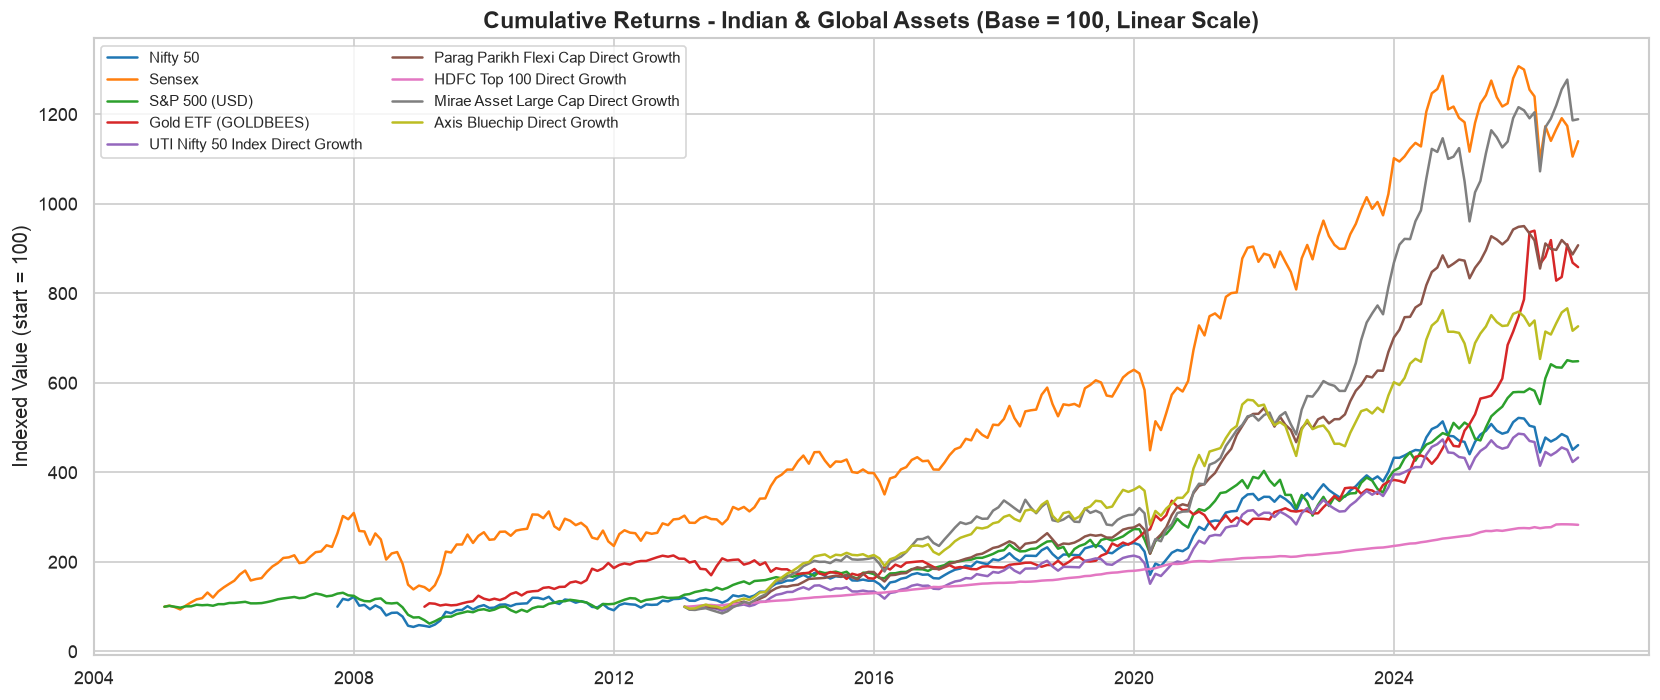

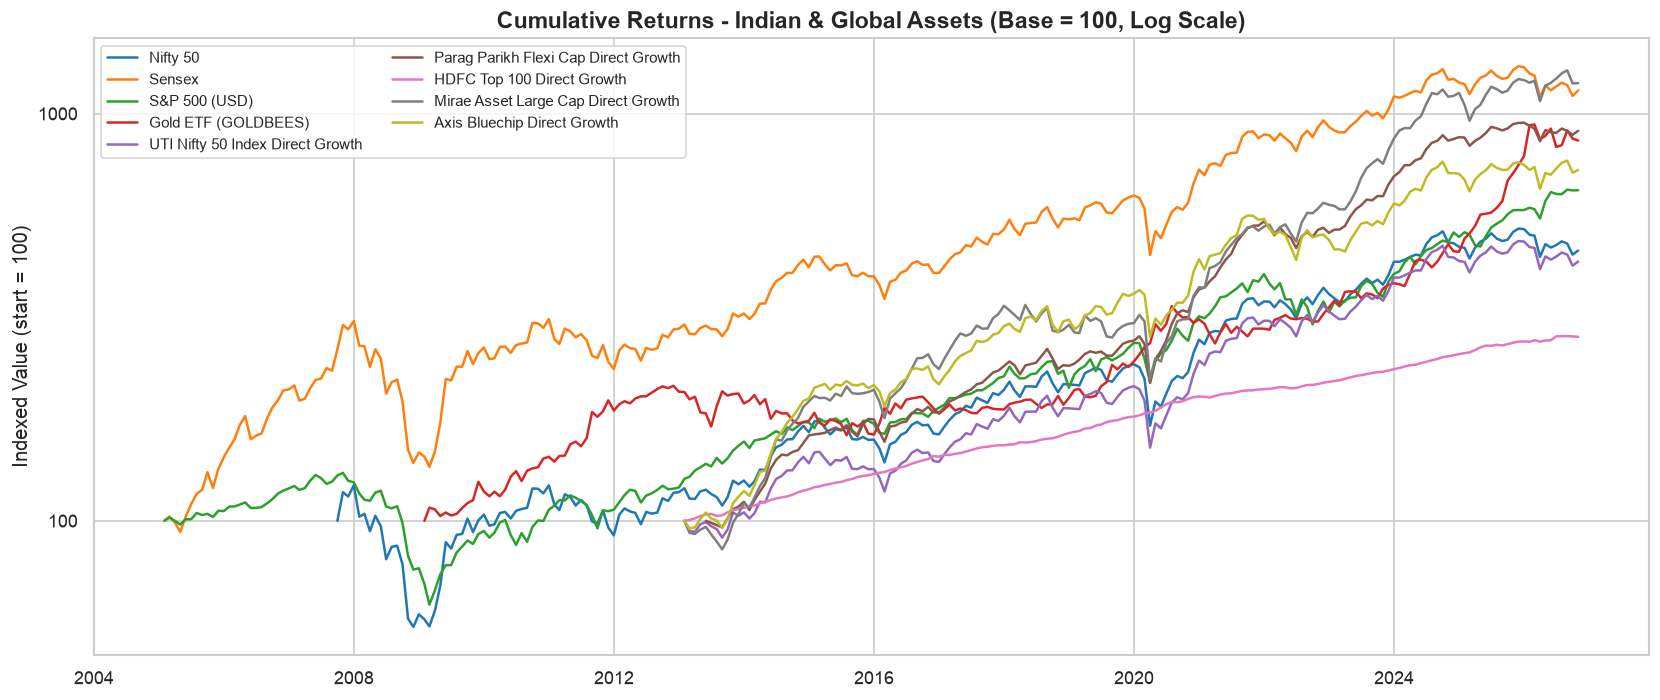


Charts saved to ../data/processed/


In [8]:
# Focused subset for the main charts: indices + gold + a few mutual funds
# We prefer assets with the longest history for cleaner visuals.
focus_candidates = [
    "Nifty 50",
    "Sensex",
    "S&P 500 (USD)",
    "S&P 500 (INR)",
    "Gold ETF (GOLDBEES)",
    "UTI Nifty 50 Index Direct Growth",
    "Parag Parikh Flexi Cap Direct Growth",
    "HDFC Top 100 Direct Growth",
    "Mirae Asset Large Cap Direct Growth",
    "Axis Bluechip Direct Growth",
    "HDFC Midcap Opportunities Direct Growth",
]

# Keep only those that actually downloaded
focus_assets = [a for a in focus_candidates if a in all_prices_monthly.columns]
print(f"Focus assets available: {focus_assets}")

focus_prices_monthly = all_prices_monthly[focus_assets].dropna(how="all")

# Cumulative returns - linear scale
fig_lin = plot_cumulative_returns(
    focus_prices_monthly,
    title="Cumulative Returns - Indian & Global Assets (Base = 100, Linear Scale)",
    log_scale=False,
)
fig_lin.savefig("../data/processed/cumulative_returns_linear.png", bbox_inches="tight")
plt.show()

# Cumulative returns - log scale (better for long periods)
fig_log = plot_cumulative_returns(
    focus_prices_monthly,
    title="Cumulative Returns - Indian & Global Assets (Base = 100, Log Scale)",
    log_scale=True,
)
fig_log.savefig("../data/processed/cumulative_returns_log.png", bbox_inches="tight")
plt.show()

print("\nCharts saved to ../data/processed/")

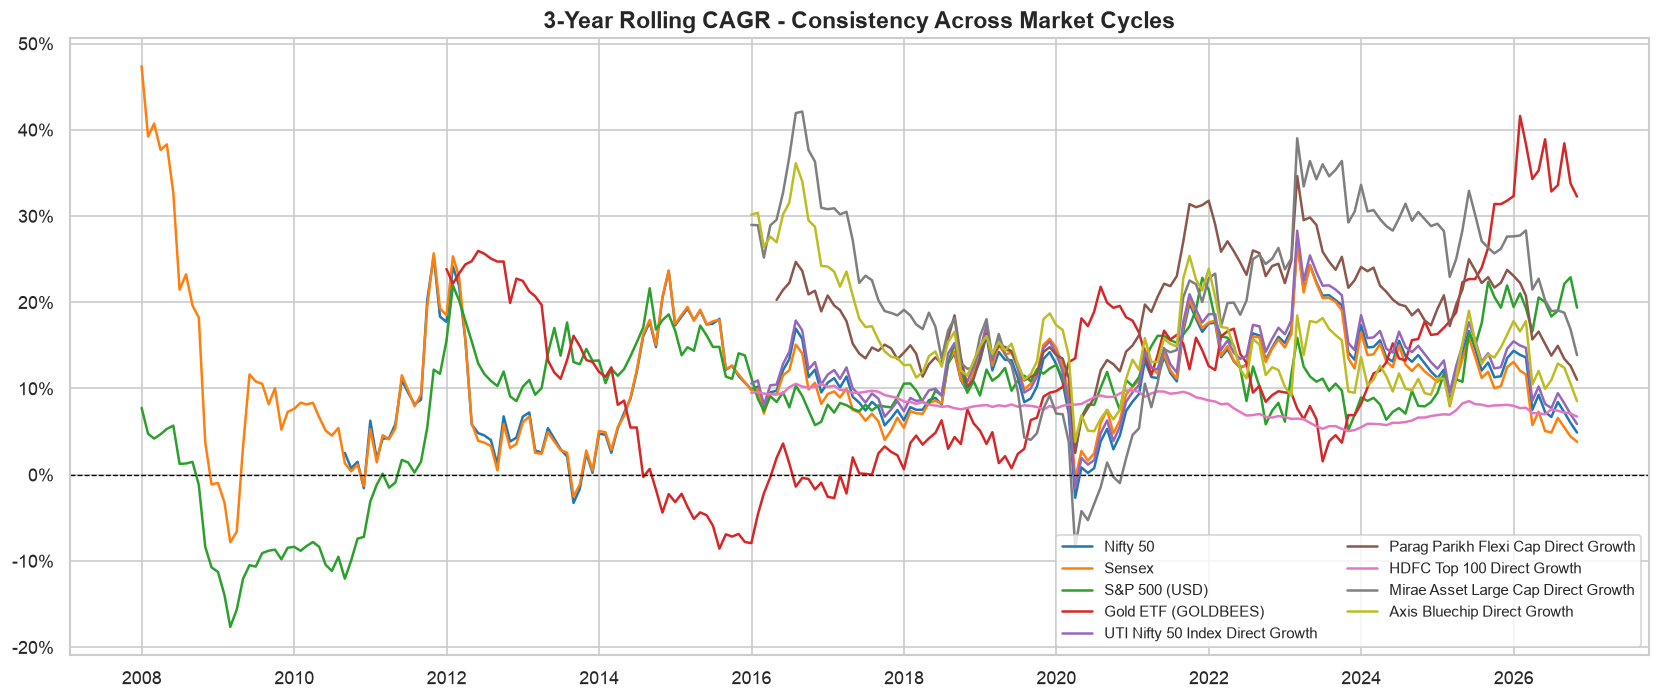

Rolling CAGR chart saved.


In [9]:
# Rolling 3-year CAGR - shows consistency of returns across market cycles
rolling_3y = {}
for name in focus_assets:
    series = all_prices_monthly[name].dropna()
    if len(series) >= 37:  # need at least 3 years + 1
        rolling_3y[name] = rolling_cagr(series, window_years=3)

if rolling_3y:
    fig_roll = plot_rolling_cagr(
        rolling_3y,
        window_years=3,
        title="3-Year Rolling CAGR - Consistency Across Market Cycles",
    )
    fig_roll.savefig("../data/processed/rolling_3y_cagr.png", bbox_inches="tight")
    plt.show()
    print("Rolling CAGR chart saved.")
else:
    print("Insufficient data for rolling CAGR chart.")

## Section 4 — Risk Analysis

### Metrics Explained

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **Sharpe Ratio** | (Return - Rf) / Vol | Return per unit of total risk. Higher is better. > 1 is good, > 1.5 is excellent. |
| **Sortino Ratio** | (Return - Rf) / Downside Vol | Like Sharpe but only penalises downward volatility. More relevant for investors who dislike losses asymmetrically. |
| **Max Drawdown** | min(Price / Peak - 1) | Worst peak-to-trough loss in the period. Tests stomach for pain — the Nifty fell ~60% in the 2008 GFC. |
| **Calmar Ratio** | CAGR / |Max Drawdown| | Return earned per unit of maximum drawdown. Higher is better. |
| **VaR 95%** | 5th percentile monthly return | In 1 out of 20 months, losses will exceed this level. A measure of tail risk. |

### Why Correlations Matter

A portfolio's risk is determined not just by the risk of individual assets but also by how they move together. An asset with modest standalone returns but **low correlation** with the rest of the portfolio can significantly reduce overall portfolio risk — this is the mathematical core of diversification (Markowitz 1952).

Gold's historically low correlation (~0.1-0.2) with Indian equities is its primary investment case, not its standalone return.

In [10]:
# Build focused price and return dicts for analysis subset
analysis_assets = [a for a in focus_assets if a in all_prices_monthly.columns]

analysis_prices = {name: all_prices_monthly[name].dropna() for name in analysis_assets}
analysis_returns = {
    name: all_returns_monthly[name].dropna()
    for name in analysis_assets
    if name in all_returns_monthly.columns
}

print(f"Analysis subset: {len(analysis_assets)} assets")
for name in analysis_assets:
    p = analysis_prices.get(name)
    r = analysis_returns.get(name)
    if p is not None and r is not None:
        print(f"  {name:<50s}  prices: {len(p)}, returns: {len(r)}")

Analysis subset: 9 assets
  Nifty 50                                            prices: 230, returns: 229
  Sensex                                              prices: 262, returns: 261
  S&P 500 (USD)                                       prices: 262, returns: 261
  Gold ETF (GOLDBEES)                                 prices: 214, returns: 213
  UTI Nifty 50 Index Direct Growth                    prices: 166, returns: 165
  Parag Parikh Flexi Cap Direct Growth                prices: 162, returns: 161
  HDFC Top 100 Direct Growth                          prices: 166, returns: 165
  Mirae Asset Large Cap Direct Growth                 prices: 166, returns: 165
  Axis Bluechip Direct Growth                         prices: 166, returns: 165


In [11]:
# Full performance summary table
summary_df = summary_table(
    price_dict=analysis_prices,
    returns_dict=analysis_returns,
    rf_annual=RF_ANNUAL,
)

pd.set_option("display.float_format", "{:.2f}".format)
print("\nFull Performance Summary")
print("=" * 90)
print(summary_df.to_string())


Full Performance Summary
                                      CAGR (%)  Ann. Vol (%)  Sharpe  Sortino  Max DD (%)  Calmar  VaR 95% (monthly, %)
Asset                                                                                                                  
Nifty 50                                  8.34         20.44    0.18     0.24      -55.12    0.15                  7.03
Sensex                                   11.84         20.29    0.34     0.46      -56.17    0.21                  7.51
S&P 500 (USD)                             8.98         14.80    0.22     0.28      -52.56    0.17                  7.18
Gold ETF (GOLDBEES)                      12.88         15.15    0.45     0.83      -24.42    0.53                  5.45
UTI Nifty 50 Index Direct Growth         11.25         15.75    0.35     0.47      -29.35    0.38                  5.79
Parag Parikh Flexi Cap Direct Growth     17.86         12.97    0.84     1.00      -23.13    0.77                  4.58
HDFC Top 100 D

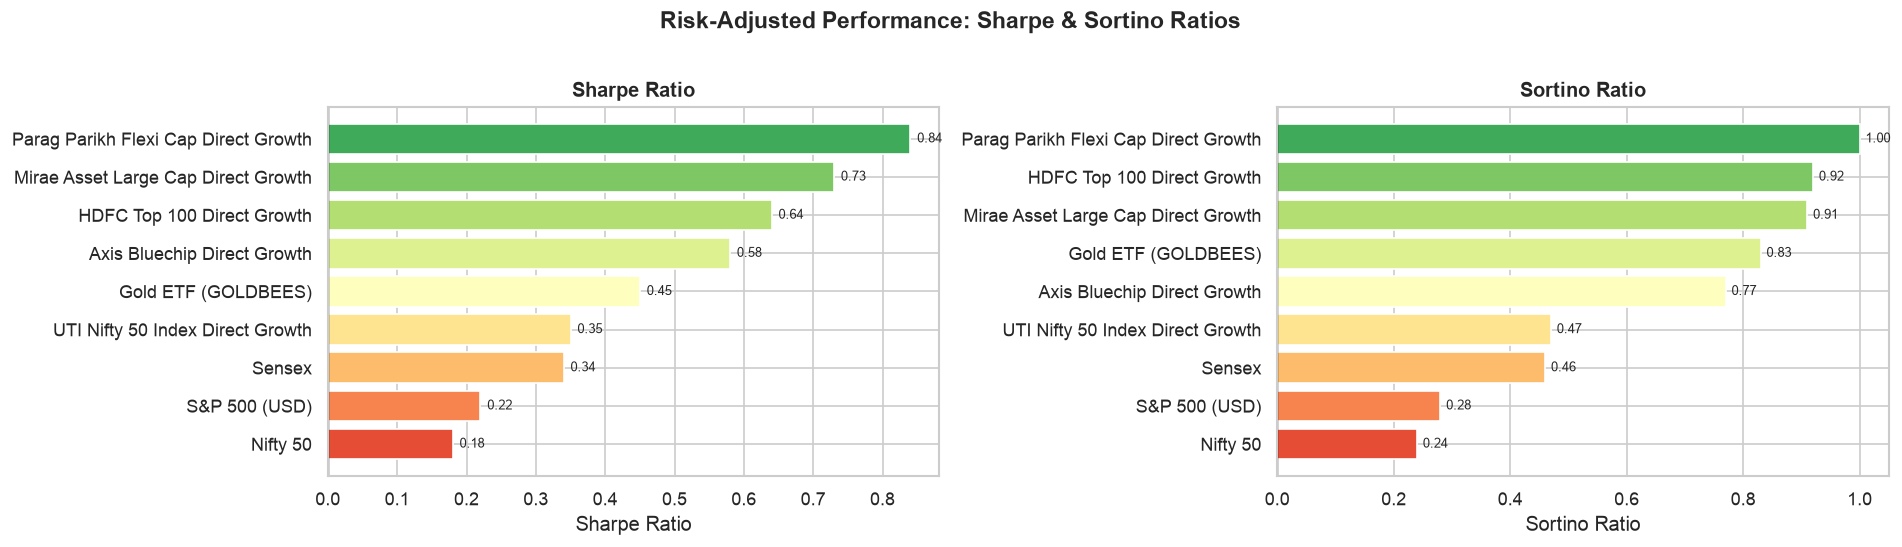

In [12]:
# Side-by-side Sharpe and Sortino bar charts
if not summary_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, max(4, len(summary_df) * 0.5)))

    # Sharpe
    sharpe_vals = summary_df["Sharpe"].sort_values(ascending=True)
    colors_s = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(sharpe_vals)))
    axes[0].barh(sharpe_vals.index, sharpe_vals.values, color=colors_s)
    axes[0].axvline(0, color="black", linewidth=0.8)
    axes[0].set_title("Sharpe Ratio", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Sharpe Ratio")
    for i, v in enumerate(sharpe_vals.values):
        axes[0].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)

    # Sortino
    sortino_vals = summary_df["Sortino"].sort_values(ascending=True)
    colors_t = plt.cm.RdYlGn(np.linspace(0.15, 0.85, len(sortino_vals)))
    axes[1].barh(sortino_vals.index, sortino_vals.values, color=colors_t)
    axes[1].axvline(0, color="black", linewidth=0.8)
    axes[1].set_title("Sortino Ratio", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Sortino Ratio")
    for i, v in enumerate(sortino_vals.values):
        axes[1].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)

    plt.suptitle(
        "Risk-Adjusted Performance: Sharpe & Sortino Ratios", fontsize=14, fontweight="bold", y=1.01
    )
    plt.tight_layout()
    plt.savefig("../data/processed/sharpe_sortino_bar.png", bbox_inches="tight")
    plt.show()
else:
    print("Summary DataFrame is empty - no data to plot.")

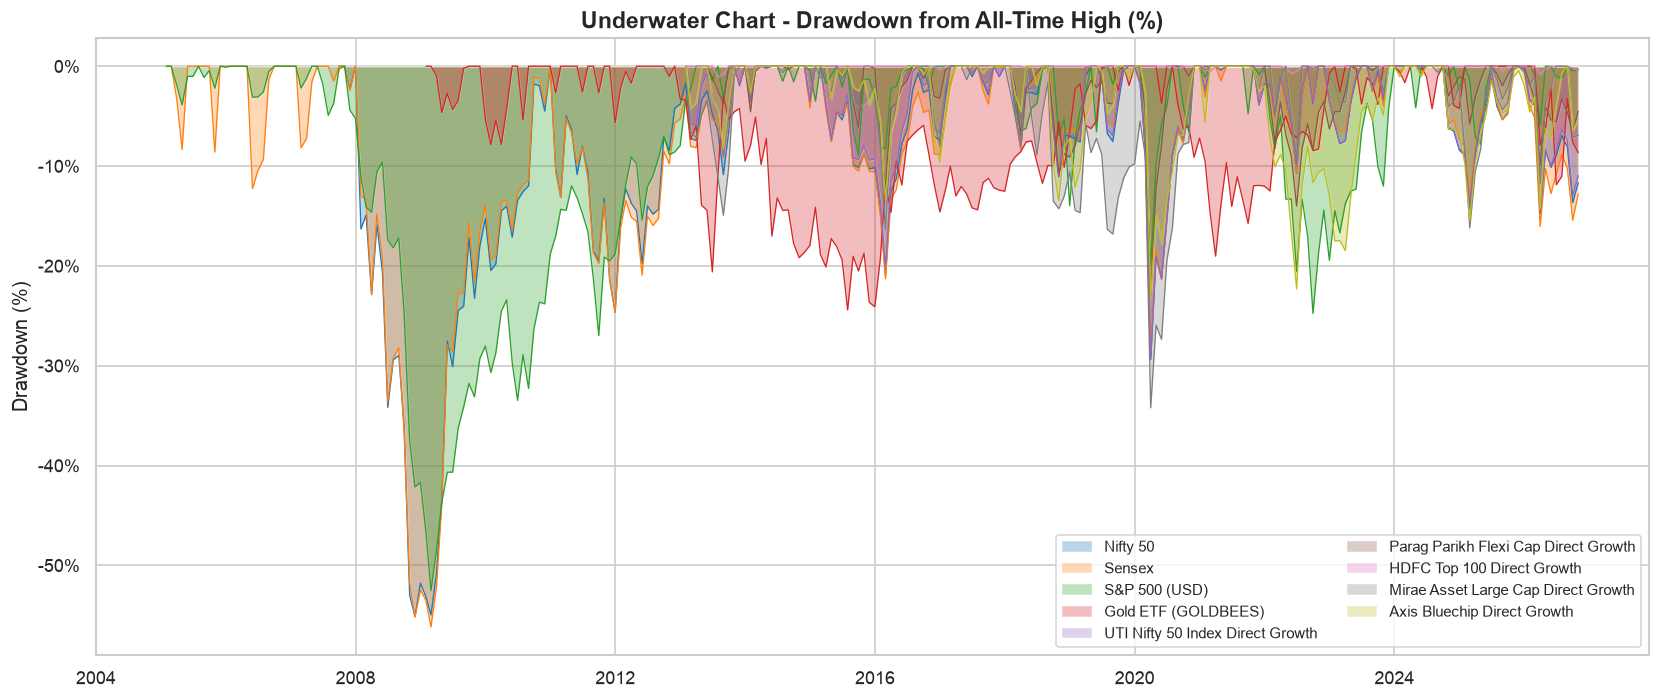

In [13]:
# Drawdown underwater chart
drawdown_dict = {}
for name, prices in analysis_prices.items():
    if len(prices) >= 13:
        drawdown_dict[name] = drawdown_series(prices)

if drawdown_dict:
    dd_df = pd.DataFrame(drawdown_dict).dropna(how="all")
    fig_dd = plot_drawdowns(
        dd_df,
        title="Underwater Chart - Drawdown from All-Time High (%)",
    )
    fig_dd.savefig("../data/processed/drawdowns.png", bbox_inches="tight")
    plt.show()
else:
    print("No drawdown data available.")

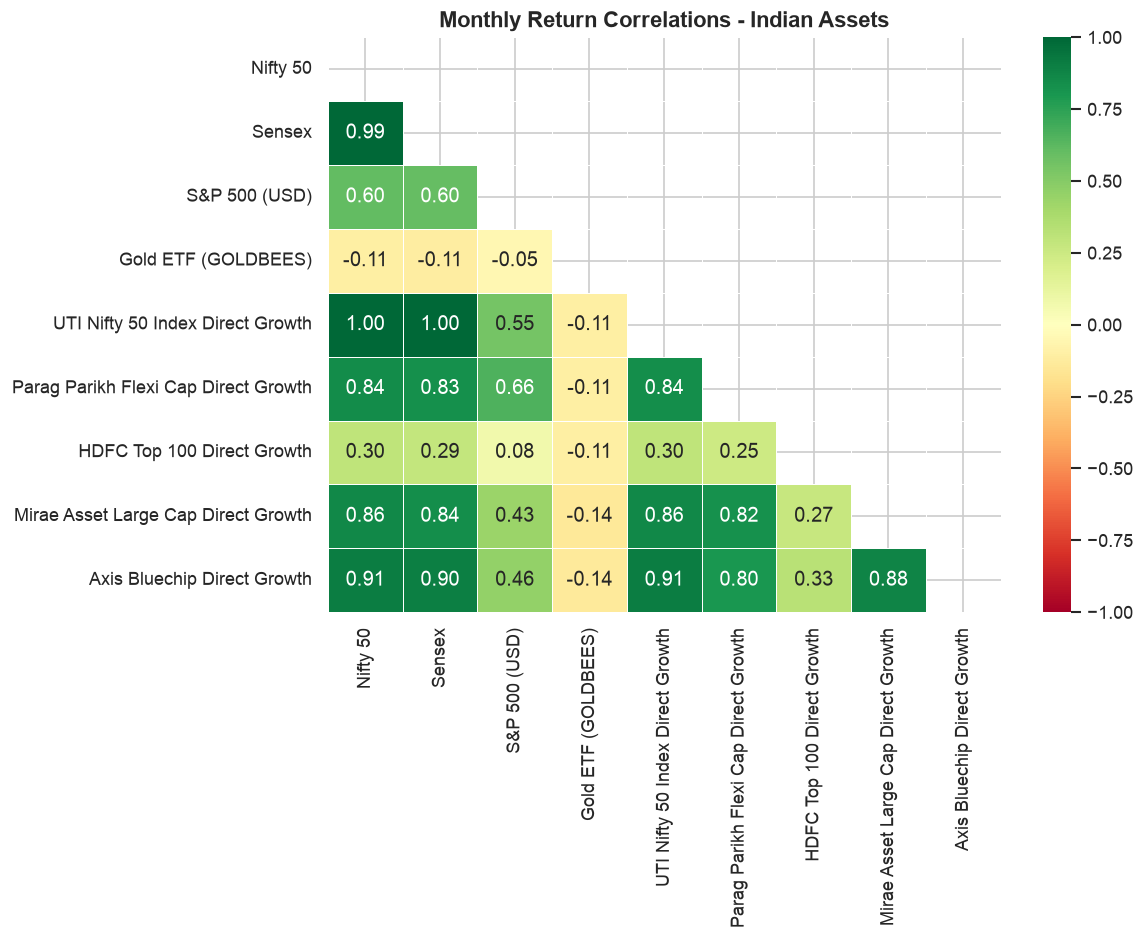

In [14]:
# Correlation heatmap
ret_for_corr = all_returns_monthly[analysis_assets].dropna(how="all")
if not ret_for_corr.empty and ret_for_corr.shape[1] > 1:
    fig_corr = plot_correlation_heatmap(
        ret_for_corr,
        title="Monthly Return Correlations - Indian Assets",
    )
    fig_corr.savefig("../data/processed/correlation_heatmap.png", bbox_inches="tight")
    plt.show()
else:
    print("Insufficient data for correlation heatmap.")

> **Gold Diversification Note**: Gold ETF (GOLDBEES) typically exhibits a correlation of **~0.1-0.2** with Nifty 50 and Sensex. This means gold prices move largely independently of equity prices. In periods of equity market stress (GFC 2008, COVID 2020), gold often rises while equities fall — making it a true portfolio diversifier. However, the primary role of gold in a portfolio should be **risk reduction**, not return enhancement. Gold's real return over very long periods is modest (~1-2% above inflation historically), and its post-Budget-2024 LTCG tax of 12.5% (with no indexation benefit) makes it less tax-efficient than before.

## Section 5 — SIP Simulation (Rs 10,000/month)

### What is a Systematic Investment Plan (SIP)?

A **SIP** invests a fixed amount at regular intervals (typically monthly). It is the most popular mechanism for Indian retail investors — over Rs 26,000 crore invested monthly as of late 2026.

### Rupee Cost Averaging

Investing a fixed rupee amount means you automatically buy:
- **More units when prices are low** (bear markets)
- **Fewer units when prices are high** (bull markets)

This lowers your average cost per unit over time and removes the need to time the market.

### ⚠️ Start-Date Fairness: Why We Use a Common Start Date

If each SIP starts when its data first becomes available, the comparison is misleading:
- Nifty 50 / S&P 500 data goes back to 2005 → more months invested → larger absolute corpus.
- Most direct-plan mutual fund NAVs only start ~2013 → fewer deposits → looks smaller.

This is **not** a return difference — it's purely a timing artifact. We fix it by running **all SIPs from the same common start date** (the latest first-available date across all analysis assets), so total invested rupees are identical for every asset and the comparison is fair.

### SIP vs Lump Sum

Mathematically, lump sum wins on average in efficient markets (~60% of the time). But SIP is behaviorally superior for salaried investors, removes timing risk, and is practically how most people invest. Both are shown in Section 5.4.

### S&P 500 (INR) vs S&P 500 (USD) — and Why Taxation Differs

The S&P 500 (INR) series multiplies the USD index price by the USD/INR exchange rate daily. This reflects the **actual return an Indian investor earns** by holding a US market exposure:
- USD/INR has moved from ~45 (2005) → ~84 (2025) → ~86+ (late 2026), giving a tailwind of ~3–4% per year in INR terms on top of the USD return.

**Critical tax difference for Indian investors (FY 2024-25 rules):**

| Route | How you invest | Tax treatment |
|-------|---------------|---------------|
| Nifty 50 / Sensex ETF or Index Fund | NSE-listed ETF, direct MF | Equity LTCG: **12.5%** after 12 months (₹1.25L exempt) |
| Indian S&P 500 MF (e.g. Motilal Oswal S&P 500) | Indian fund holding US stocks | **Slab rate** (20–30%) — treated as debt post Apr-2023 |
| Direct US ETF via LRS (Vested, INDmoney, etc.) | Buy VOO/IVV on NYSE directly | Foreign equity: LTCG **12.5%** after 24 months |

The middle route (Indian S&P 500 mutual funds) is the most tax-inefficient due to the Apr-2023 rule change that reclassified international equity funds as debt for tax purposes. If you want S&P 500 exposure from India, the LRS route (direct purchase) or a fund-of-fund that maintains 65%+ domestic equity allocation is more tax-efficient.

In [15]:
# Determine a common SIP start date so every asset has the same investment period.
# This prevents the start-date bias where assets with longer history look bigger
# simply because more monthly deposits were made — not because of better returns.

candidate_starts = {}
sip_asset_list = list(analysis_assets)
if "S&P 500 (INR)" in all_prices_raw:
    sip_asset_list = sip_asset_list + ["S&P 500 (INR)"]
    # make sure it's in analysis_prices too
    analysis_prices["S&P 500 (INR)"] = (
        all_prices_raw["S&P 500 (INR)"].resample("ME").last().dropna()
    )

for name in sip_asset_list:
    if name in all_prices_raw:
        first = all_prices_raw[name].dropna().index[0]
        candidate_starts[name] = first

# Common start = latest first-available date (all assets have data from here)
if candidate_starts:
    COMMON_SIP_START = max(candidate_starts.values()).strftime("%Y-%m-%d")
else:
    COMMON_SIP_START = START_DATE

print(f"Common SIP start date : {COMMON_SIP_START}")
print(f"\nIndividual data start dates (sorted):")
for name, dt in sorted(candidate_starts.items(), key=lambda x: x[1]):
    note = " ← common start" if dt.strftime("%Y-%m-%d") == COMMON_SIP_START else ""
    print(f"  {name:<52s}  {dt.date()}{note}")

# Run SIP simulation for all assets from the common start date
sip_results = {}
for name in sip_asset_list:
    if name in all_prices_raw:
        try:
            sip_results[name] = simulate_sip(
                all_prices_raw[name],
                monthly_amount=MONTHLY_SIP,
                start=COMMON_SIP_START,
            )
            n_y = sip_results[name]["n_years"]
            corpus = sip_results[name]["final_value"]
            cagr_val = sip_results[name]["cagr_approx"] * 100
            print(f"  [OK] {name:<52s}  {n_y:.1f}y  corpus Rs{corpus:,.0f}  CAGR {cagr_val:.1f}%")
        except Exception as e:
            print(f"  [SKIP] {name}: {e}")
    else:
        print(f"  [MISS] {name} not in all_prices_raw")

print(
    f"\nSIP simulations completed for {len(sip_results)} assets (common start: {COMMON_SIP_START})."
)

Common SIP start date : 2013-05-28

Individual data start dates (sorted):
  Sensex                                                2005-01-03
  S&P 500 (USD)                                         2005-01-03
  S&P 500 (INR)                                         2005-01-03
  Nifty 50                                              2007-09-17
  Gold ETF (GOLDBEES)                                   2009-01-02
  Mirae Asset Large Cap Direct Growth                   2013-01-01
  UTI Nifty 50 Index Direct Growth                      2013-01-02
  HDFC Top 100 Direct Growth                            2013-01-02
  Axis Bluechip Direct Growth                           2013-01-02
  Parag Parikh Flexi Cap Direct Growth                  2013-05-28 ← common start
  [OK] Nifty 50                                              13.4y  corpus Rs3,218,578  CAGR 5.2%
  [OK] Sensex                                                13.4y  corpus Rs3,133,400  CAGR 5.0%
  [OK] S&P 500 (USD)                         

In [16]:
# SIP summary table (all simulations run from the same start date)
sip_rows = []
for name, res in sip_results.items():
    hist = res["history"]
    sip_rows.append(
        {
            "Asset": name,
            "SIP Start": hist.index[0].date(),
            "Period (Years)": round(res["n_years"], 1),
            "Total Invested (Rs)": f"Rs {res['total_invested']:,.0f}",
            "Final Corpus (Rs)": f"Rs {res['final_value']:,.0f}",
            "Absolute Return (%)": f"{res['absolute_return_pct']:.1f}%",
            "CAGR (Approx %)": f"{res['cagr_approx'] * 100:.2f}%",
            "Wealth Multiplier": f"{res['final_value'] / res['total_invested']:.2f}x",
        }
    )

sip_summary = (
    pd.DataFrame(sip_rows).set_index("Asset").sort_values("CAGR (Approx %)", ascending=False)
)
print(f"\nSIP Simulation Summary - Rs {MONTHLY_SIP:,}/month (common start: {COMMON_SIP_START})")
print("Total invested is identical for all assets — differences reflect only return, not tenure.")
print("=" * 110)
print(sip_summary.to_string())


SIP Simulation Summary - Rs 10,000/month (common start: 2013-05-28)
Total invested is identical for all assets — differences reflect only return, not tenure.
                                       SIP Start  Period (Years) Total Invested (Rs) Final Corpus (Rs) Absolute Return (%) CAGR (Approx %) Wealth Multiplier
Asset                                                                                                                                                       
S&P 500 (INR)                         2013-05-31           13.40        Rs 1,620,000      Rs 5,603,911              245.9%           9.69%             3.46x
Parag Parikh Flexi Cap Direct Growth  2013-05-31           13.40        Rs 1,620,000      Rs 5,526,046              241.1%           9.58%             3.41x
Gold ETF (GOLDBEES)                   2013-05-31           13.40        Rs 1,620,000      Rs 5,412,216              234.1%           9.41%             3.34x
S&P 500 (USD)                         2013-05-31        

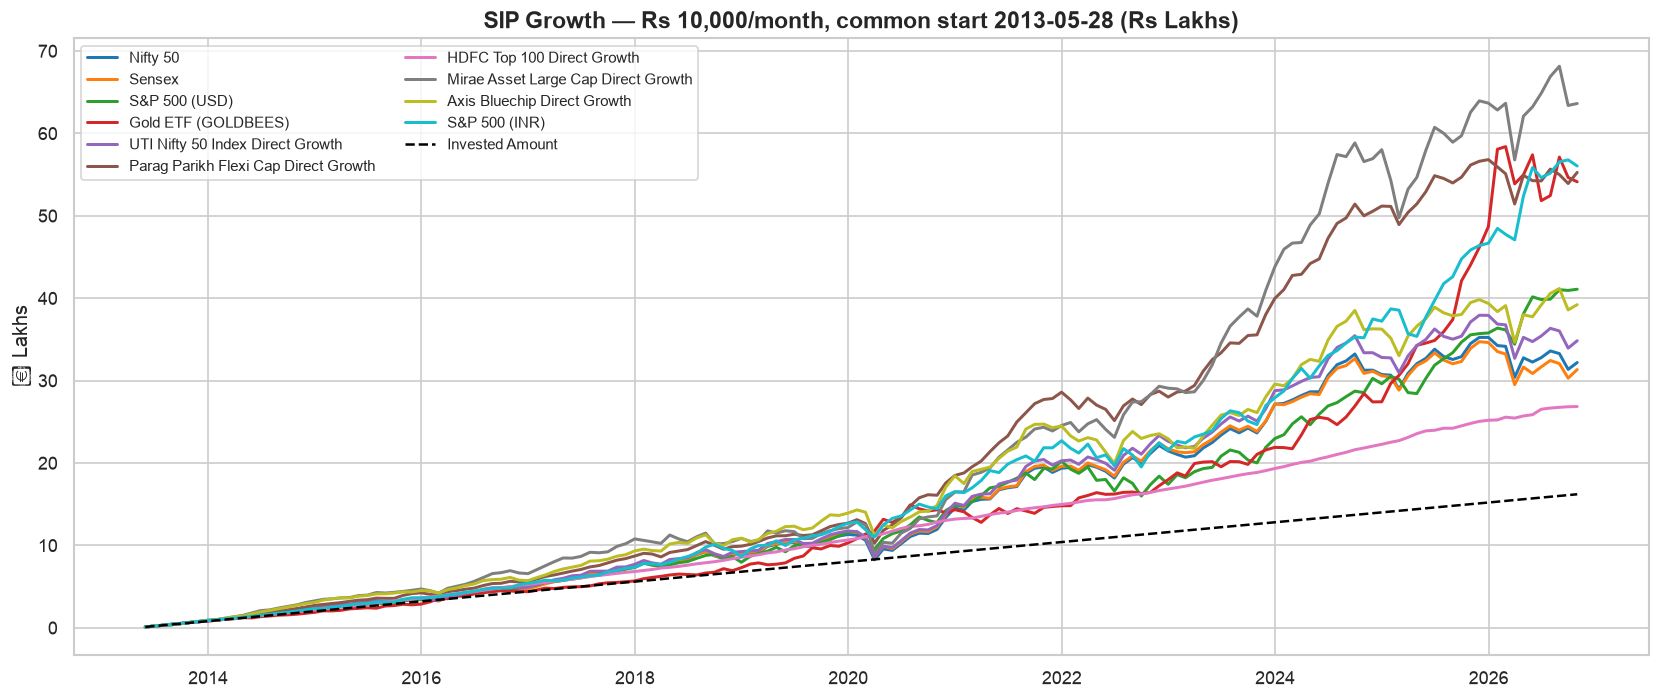

In [17]:
# Plot SIP growth curves
if sip_results:
    fig_sip = plot_sip_growth(
        sip_results,
        title=f"SIP Growth — Rs {MONTHLY_SIP:,}/month, common start {COMMON_SIP_START} (Rs Lakhs)",
    )
    fig_sip.savefig("../data/processed/sip_growth.png", bbox_inches="tight")
    plt.show()
else:
    print("No SIP results to plot.")

In [18]:
# Lump-sum vs SIP comparison for Nifty 50 and best active fund
comparison_assets = []
for name in [
    "Nifty 50",
    "UTI Nifty 50 Index Direct Growth",
    "Parag Parikh Flexi Cap Direct Growth",
    "HDFC Top 100 Direct Growth",
    "Mirae Asset Large Cap Direct Growth",
]:
    if name in analysis_prices:
        comparison_assets.append(name)

print("Lump-Sum vs SIP Comparison (Rs 1 Lakh invested)")
print("=" * 90)
rows_compare = []
for name in comparison_assets:
    prices = analysis_prices[name]
    if len(prices) < 13:
        continue
    # Lump-sum: buy at first available price, sell at last
    ls_cagr = cagr(prices)
    # SIP: from simulate_sip result if available
    sip_cagr = sip_results[name]["cagr_approx"] if name in sip_results else float("nan")
    diff = ls_cagr - sip_cagr
    rows_compare.append(
        {
            "Asset": name,
            "Lump-Sum CAGR (%)": f"{ls_cagr * 100:.2f}%",
            "SIP CAGR (approx %)": f"{sip_cagr * 100:.2f}%" if not np.isnan(sip_cagr) else "N/A",
            "LS over SIP (pp)": f"{diff * 100:+.2f}pp" if not np.isnan(sip_cagr) else "N/A",
        }
    )

compare_df = pd.DataFrame(rows_compare).set_index("Asset")
print(compare_df.to_string())
print(
    "\nKey Insight: Lump sum tends to beat SIP in bull markets (markets trend up 70% of the time)."
)
print("But SIP beats lump sum when you invest at a market peak - it removes timing risk entirely.")
print("For salaried investors who earn monthly: SIP is the rational choice.")

Lump-Sum vs SIP Comparison (Rs 1 Lakh invested)
                                     Lump-Sum CAGR (%) SIP CAGR (approx %) LS over SIP (pp)
Asset                                                                                      
Nifty 50                                         8.34%               5.25%          +3.09pp
UTI Nifty 50 Index Direct Growth                11.25%               5.87%          +5.38pp
Parag Parikh Flexi Cap Direct Growth            17.86%               9.58%          +8.29pp
HDFC Top 100 Direct Growth                       7.86%               3.84%          +4.02pp
Mirae Asset Large Cap Direct Growth             19.73%              10.73%          +9.00pp

Key Insight: Lump sum tends to beat SIP in bull markets (markets trend up 70% of the time).
But SIP beats lump sum when you invest at a market peak - it removes timing risk entirely.
For salaried investors who earn monthly: SIP is the rational choice.


## Section 6 — Cost & Tax Impact

### Why This Section Is the Most Important for Retail Investors

The single largest controllable drag on long-term investment returns is **fees**. Unlike market returns (which are uncertain), the cost you pay is locked in. Over long horizons, the compounding effect of even a small fee difference is startling:

- A 0.5% higher expense ratio on a 12% CAGR fund reduces your 20-year wealth by **~8%** (Rs 8 out of every Rs 100 of final corpus goes to fees).
- A 1.0% higher fee over 20 years costs you **~15%** of final wealth.

This is why **direct plan mutual funds** (which cut out the distributor commission of ~0.5-1.0%) are so important — the difference between regular and direct plans compounds to lakhs of rupees over a 15-20 year horizon.

### Tax Rules (India, FY 2024-25 onwards)

| Asset | Holding | Tax Rate | Notes |
|-------|---------|----------|-------|
| Equity MF / ETF / Stock | >= 12 months (LTCG) | **12.5%** on gains > Rs 1.25L/year | Budget 2024 raised from 10%/Rs 1L |
| Equity MF / ETF / Stock | < 12 months (STCG) | **20%** | Budget 2024 raised from 15% |
| Gold ETF (GOLDBEES) | >= 24 months (LTCG) | **12.5%** | No indexation benefit (Budget 2024) |
| Gold ETF | < 24 months (STCG) | Slab rate (up to 30%) | |
| Debt MF / G-Sec | Any (post Apr-2023) | **Slab rate** (up to 30%+) | No LTCG benefit anymore |

**Key implication**: G-Secs and debt funds are the most tax-inefficient for high-income investors (30% slab). For someone in the 30% bracket, a 7.5% G-Sec yield becomes just ~5.2% post-tax — barely ahead of inflation.

In [19]:
# Build expense drag comparison table
# Use the CAGR values computed in Section 3 as the gross return estimates
gross_cagrs = {}
for name in all_prices_monthly.columns:
    series = all_prices_monthly[name].dropna()
    if len(series) >= 13:
        gross_cagrs[name] = cagr(series)

# Filter to only assets we have expense ratios for
cost_assets = {k: v for k, v in gross_cagrs.items() if k in EXPENSE_RATIOS}

# Add index entries if present (with 0% expense ratio)
for idx_name in ["Nifty 50", "Sensex"]:
    if idx_name in gross_cagrs and idx_name not in cost_assets:
        cost_assets[idx_name] = gross_cagrs[idx_name]

if cost_assets:
    cost_table = build_cost_comparison_table(
        asset_returns=cost_assets,
        expense_ratios=EXPENSE_RATIOS,
        years=HOLDING_YEARS,
        invested=LUMP_SUM,
    )
    print("Expense Ratio Impact on Rs 1 Lakh Invested over 10 Years")
    print("=" * 90)
    print(cost_table.to_string())
else:
    cost_table = pd.DataFrame()
    print("No assets with expense ratio data found.")

Expense Ratio Impact on Rs 1 Lakh Invested over 10 Years
                                             Gross CAGR (%)  Expense Ratio (%)  Net CAGR (%)  Gross ₹ (after 10Y)  Net ₹ (after 10Y)  ₹ Lost to Fees
Asset                                                                                                                                               
Axis Bluechip Direct Growth                           15.52              55.00        -39.48               423110                659          422451
Mirae Asset Large Cap Direct Growth                   19.73              54.00        -34.27               605504               1506          603998
HDFC Top 100 Direct Growth                             7.86              97.00        -89.14               213097                  0          213097
SBI Bluechip Direct Growth                            13.84              79.00        -65.16               365525                  3          365522
Parag Parikh Flexi Cap Direct Growth             

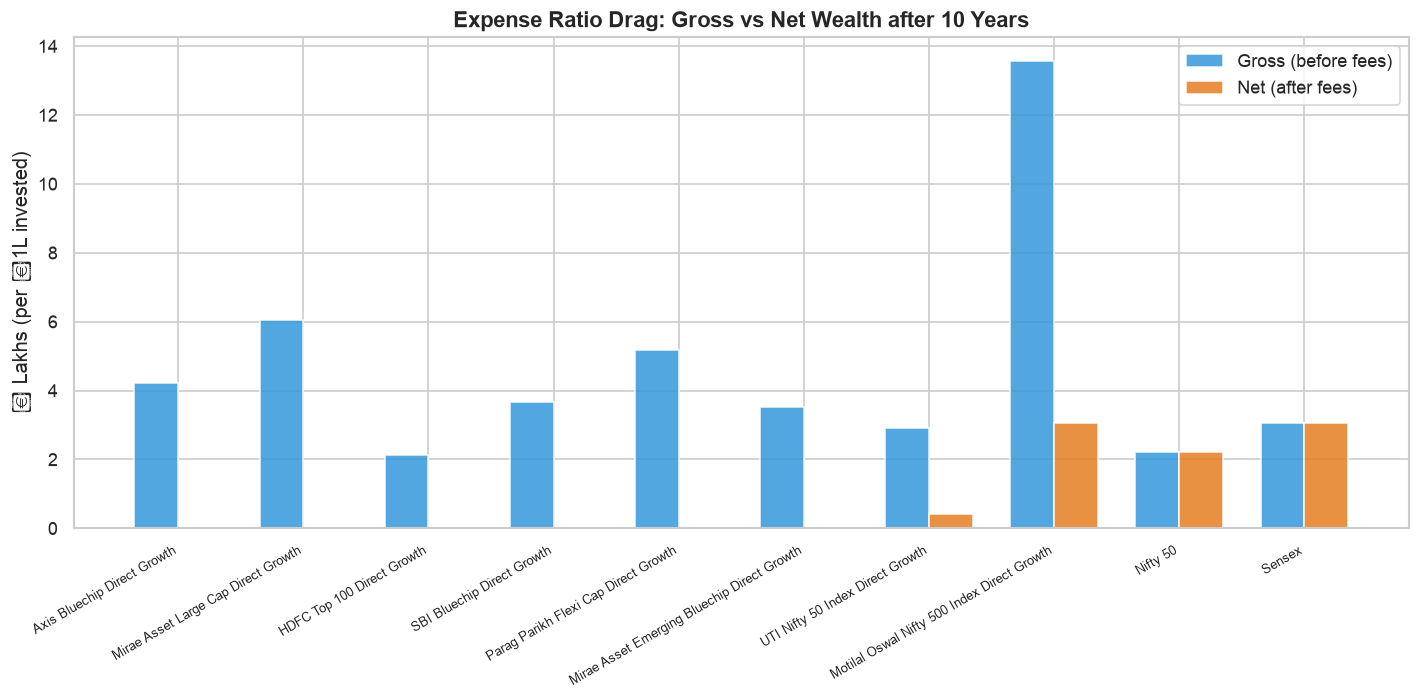

In [20]:
# Plot expense drag
if not cost_table.empty:
    fig_exp = plot_expense_drag(cost_table)
    fig_exp.savefig("../data/processed/expense_drag.png", bbox_inches="tight")
    plt.show()
else:
    print("No cost table available for plotting.")

In [21]:
# Tax impact analysis
# For each major asset class, compute after-tax CAGR over 10 years


def get_gross_cagr(name, fallback):
    if name in gross_cagrs:
        return gross_cagrs[name]
    for k in gross_cagrs:
        if name.lower() in k.lower():
            return gross_cagrs[k]
    return fallback


nifty_gross = get_gross_cagr("Nifty 50", 0.12)
gold_gross = get_gross_cagr("Gold ETF (GOLDBEES)", 0.10)
gsec_gross = float(gsec_10y.iloc[-1]) if len(gsec_10y) > 0 else 0.072
active_gross = get_gross_cagr("HDFC Top 100 Direct Growth", 0.125)
index_mf_gross = get_gross_cagr("UTI Nifty 50 Index Direct Growth", 0.118)


def total_return_10y(annual_cagr, years=10):
    return (1 + annual_cagr) ** years - 1


tax_rows = []
for label, gross_cagr_val, asset_type in [
    ("Nifty 50 Index", nifty_gross, "equity"),
    ("Active Equity MF", active_gross, "equity"),
    ("UTI Nifty 50 Index MF (Direct)", index_mf_gross, "equity"),
    ("Gold ETF (GOLDBEES)", gold_gross, "gold"),
    ("G-Sec / Debt MF", gsec_gross, "debt"),
]:
    total_ret = total_return_10y(gross_cagr_val)
    if asset_type == "equity":
        net_cagr = equity_after_tax_return(
            gross_return=total_ret,
            holding_years=HOLDING_YEARS,
            invested_amount=LUMP_SUM,
        )
    elif asset_type == "gold":
        net_cagr = gold_after_tax_return(
            gross_return=total_ret,
            holding_years=HOLDING_YEARS,
            invested_amount=LUMP_SUM,
        )
    else:
        net_cagr = debt_after_tax_return(
            gross_annual_yield=gross_cagr_val,
            holding_years=HOLDING_YEARS,
        )
    tax_rows.append(
        {
            "Asset": label,
            "Gross CAGR (%)": round(gross_cagr_val * 100, 2),
            "After-Tax CAGR (%)": round(net_cagr * 100, 2),
            "Tax Drag (pp)": round((gross_cagr_val - net_cagr) * 100, 2),
            "Gross Rs 1L grows to": f"Rs {LUMP_SUM * (1 + gross_cagr_val) ** HOLDING_YEARS:,.0f}",
            "Net-of-Tax grows to": f"Rs {LUMP_SUM * (1 + net_cagr) ** HOLDING_YEARS:,.0f}",
        }
    )

tax_df = pd.DataFrame(tax_rows).set_index("Asset")
print("After-Tax Return Analysis (30% slab for debt, LTCG for equity/gold)")
print("=" * 90)
print(tax_df.to_string())

After-Tax Return Analysis (30% slab for debt, LTCG for equity/gold)
                                Gross CAGR (%)  After-Tax CAGR (%)  Tax Drag (pp) Gross Rs 1L grows to Net-of-Tax grows to
Asset                                                                                                                     
Nifty 50 Index                            8.34                8.34           0.00           Rs 222,704          Rs 222,704
Active Equity MF                          7.86                7.86           0.00           Rs 213,097          Rs 213,097
UTI Nifty 50 Index MF (Direct)           11.25               10.92           0.33           Rs 290,489          Rs 281,975
Gold ETF (GOLDBEES)                      12.88                7.45           5.43           Rs 335,867          Rs 205,204
G-Sec / Debt MF                           7.50                5.16           2.34           Rs 206,103          Rs 165,389


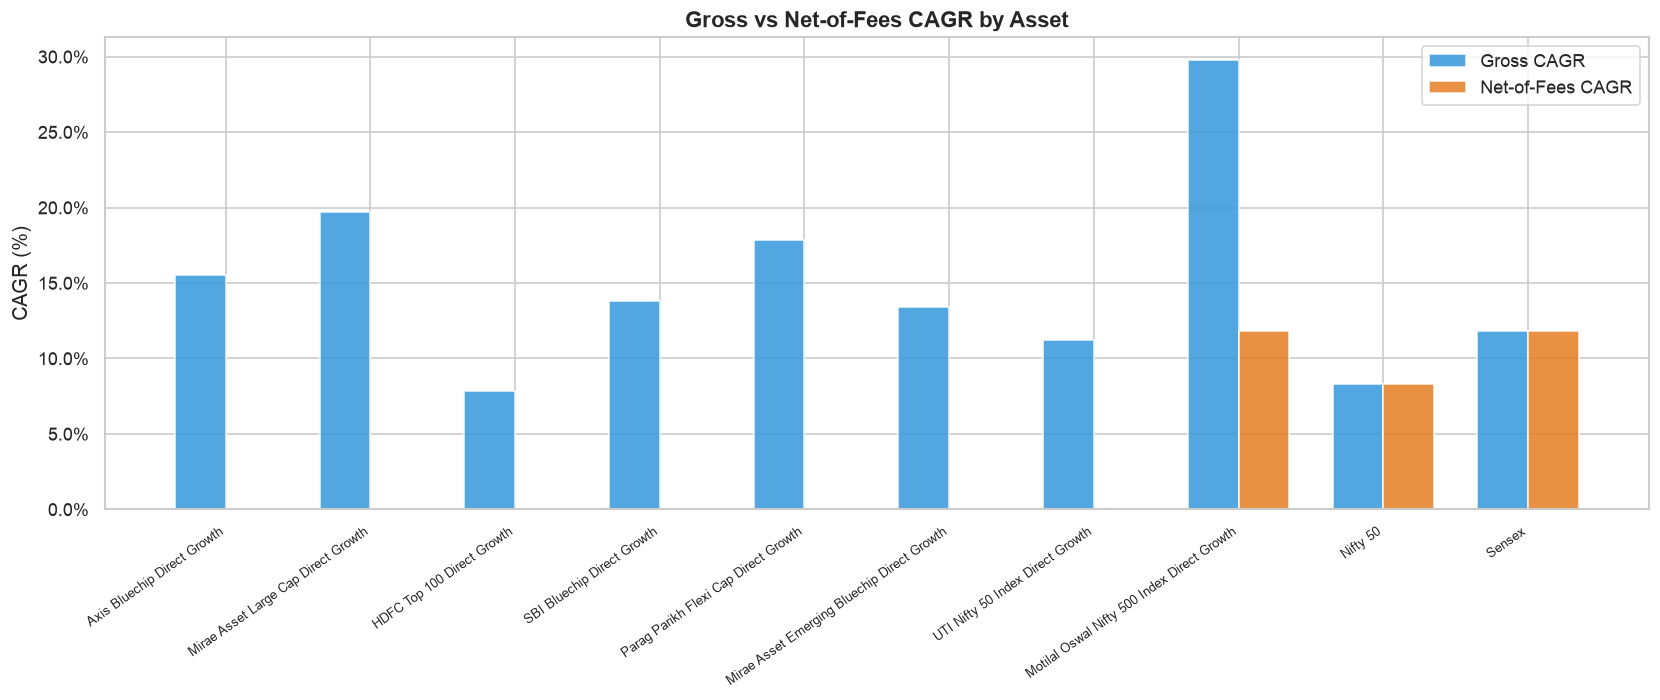

In [22]:
# Grouped bar chart: gross vs net-of-cost CAGR
if not cost_table.empty:
    labels = list(cost_assets.keys())
    gross_vals = [gross_cagrs.get(n, 0) * 100 for n in labels]
    net_cost_vals = [
        max(0, gross_cagrs.get(n, 0) - EXPENSE_RATIOS.get(n, 0.0)) * 100 for n in labels
    ]

    x = np.arange(len(labels))
    width = 0.35
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(x - width / 2, gross_vals, width, label="Gross CAGR", color="#3498db", alpha=0.85)
    ax.bar(
        x + width / 2, net_cost_vals, width, label="Net-of-Fees CAGR", color="#e67e22", alpha=0.85
    )
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("CAGR (%)")
    ax.set_title("Gross vs Net-of-Fees CAGR by Asset", fontsize=13, fontweight="bold")
    ax.legend()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}%"))
    plt.tight_layout()
    plt.savefig("../data/processed/gross_net_cagr_comparison.png", bbox_inches="tight")
    plt.show()
else:
    print("Cost table not available for CAGR comparison chart.")

In [23]:
# What does Rs 1 lakh grow to in 10 years - after all costs and taxes?
print("What does Rs 1 Lakh grow to in 10 years? (After fees & taxes)")
print("=" * 70)
print(f"{'Asset':<45} {'Gross Final':>12} {'Net Final':>12} {'Difference':>12}")
print("-" * 70)

for asset_name, row in tax_df.iterrows():
    g = row["Gross CAGR (%)"] / 100
    n = row["After-Tax CAGR (%)"] / 100
    gross_final = LUMP_SUM * (1 + g) ** HOLDING_YEARS
    net_final = LUMP_SUM * (1 + n) ** HOLDING_YEARS
    diff = gross_final - net_final
    print(
        f"{str(asset_name).ljust(45)} Rs{gross_final:>10,.0f}  Rs{net_final:>10,.0f}  Rs{diff:>10,.0f}"
    )

print("-" * 70)
print("\nConclusion: Tax treatment significantly differentiates net returns.")
print("Equity LTCG (12.5%) < Gold LTCG (12.5%) < Debt slab rate (30%).")
print("For a 30% bracket investor, debt is the least tax-efficient asset class.")

What does Rs 1 Lakh grow to in 10 years? (After fees & taxes)
Asset                                          Gross Final    Net Final   Difference
----------------------------------------------------------------------
Nifty 50 Index                                Rs   222,786  Rs   222,786  Rs         0
Active Equity MF                              Rs   213,110  Rs   213,110  Rs         0
UTI Nifty 50 Index MF (Direct)                Rs   290,402  Rs   281,902  Rs     8,500
Gold ETF (GOLDBEES)                           Rs   335,869  Rs   205,147  Rs   130,723
G-Sec / Debt MF                               Rs   206,103  Rs   165,389  Rs    40,714
----------------------------------------------------------------------

Conclusion: Tax treatment significantly differentiates net returns.
Equity LTCG (12.5%) < Gold LTCG (12.5%) < Debt slab rate (30%).
For a 30% bracket investor, debt is the least tax-efficient asset class.


## Section 7 — Fama-French Factor Analysis

### The Theory

#### CAPM (Sharpe 1964, Lintner 1965)
The Capital Asset Pricing Model says: *all systematic return differences are explained by exposure to the market portfolio.*

*r_i - r_f = alpha + beta * (r_m - r_f) + epsilon*

Jensen's alpha (alpha) measures the manager's value-add above what the market beta earns. If alpha = 0 after fees, active management adds no value.

#### Fama-French 3-Factor Model (1993)
FF3 adds two additional risk factors:
- **SMB** (Small Minus Big): small-cap premium — reward for bearing illiquidity/distress risk of smaller firms.
- **HML** (High Minus Low): value premium — reward for holding cheap (high book/market) vs expensive (low book/market) companies.

A fund's alpha in FF3 is what remains after controlling for its exposure to these well-documented systematic factors.

#### Carhart 4-Factor Model (1997)
Adds **MOM** (Momentum): recent 12-month winners tend to keep winning for the next 3-12 months. A fund that buys winners and sells losers earns this premium systematically, not through skill.

#### Factor Premia in India (Wahal & Yezdi 2018)
- **SMB (size)**: Positive but smaller and less significant than in the US. The Indian small-cap universe is thinner and more volatile.
- **HML (value)**: Positive and statistically significant. Value investing works in India.
- **MOM (momentum)**: Strongly positive and significant. The most robust premium in India.

#### Our Factor Construction
We construct factor proxies from NSE ETF prices:
- **Mkt-Rf**: Nifty 50 return minus monthly RBI repo rate
- **SMB**: Nifty Next 50 ETF (JUNIORBEES) minus Nifty 50 (larger-cap anchor)
- **HML**: Value ETF (NV20BEES) minus Nifty 50
- **MOM**: Momentum ETF (MOM100) minus Nifty 50

> **Caveat**: These are proxy factors constructed from index ETFs, not the pure academic SMB/HML factors that require stock-level sorting. For rigorous research, use Compustat India data or AQR's India factor library. The proxies here are available to any investor and reflect investable factor premia.

In [24]:
# Build factor returns from available price data
try:
    factors = build_factor_returns(all_prices_raw, rf_series=rf_daily)
    print("Factor returns constructed:")
    print(
        f"  Mkt-Rf : {len(factors.mkt_rf)} monthly obs  "
        f"(range: {factors.mkt_rf.index[0].date()} - {factors.mkt_rf.index[-1].date()})"
    )
    if factors.smb is not None:
        print(f"  SMB    : {len(factors.smb)} obs")
    else:
        print("  SMB    : Not available (JUNIORBEES data missing)")
    if factors.hml is not None:
        print(f"  HML    : {len(factors.hml)} obs")
    else:
        print("  HML    : Not available (NV20BEES data missing)")
    if factors.mom is not None:
        print(f"  MOM    : {len(factors.mom)} obs")
    else:
        print("  MOM    : Not available (MOM100 data missing)")
    if factors.qmj is not None:
        print(f"  QMJ    : {len(factors.qmj)} obs")
    else:
        print("  QMJ    : Not available (QUAL30IETF data missing)")
except Exception as e:
    print(f"Factor construction failed: {e}")
    factors = None

Factor construction failed: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


In [25]:
# Plot factor return series: cumulative log returns
if factors is not None:
    factor_series = {"Mkt-Rf": factors.mkt_rf}
    if factors.smb is not None:
        factor_series["SMB"] = factors.smb
    if factors.hml is not None:
        factor_series["HML"] = factors.hml
    if factors.mom is not None:
        factor_series["MOM"] = factors.mom

    fig, ax = plt.subplots(figsize=(14, 6))
    for fname, fseries in factor_series.items():
        cum_log = np.log1p(fseries).cumsum() * 100  # cumulative log return in %
        ax.plot(cum_log.index, cum_log.values, label=fname, linewidth=1.8)

    # Shade GFC and COVID recession periods
    ax.axvspan(
        pd.Timestamp("2008-01-01"),
        pd.Timestamp("2009-03-31"),
        alpha=0.12,
        color="red",
        label="GFC 2008-09",
    )
    ax.axvspan(
        pd.Timestamp("2020-01-01"),
        pd.Timestamp("2020-06-30"),
        alpha=0.12,
        color="orange",
        label="COVID 2020",
    )

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(
        "Cumulative Factor Returns (Log Scale) - Indian Market Proxies",
        fontsize=13,
        fontweight="bold",
    )
    ax.set_ylabel("Cumulative Log Return (%)")
    ax.legend(fontsize=9, ncol=2)
    plt.tight_layout()
    plt.savefig("../data/processed/factor_returns.png", bbox_inches="tight")
    plt.show()
else:
    print("Factors not available - skipping plot.")

Factors not available - skipping plot.


In [26]:
# Factor premium statistics
if factors is not None:
    factor_stats = []
    for fname, fseries in factor_series.items():
        ann_ret = fseries.mean() * 12
        ann_vol = fseries.std() * np.sqrt(12)
        sr = ann_ret / ann_vol if ann_vol > 0 else np.nan
        factor_stats.append(
            {
                "Factor": fname,
                "Ann. Mean Return (%)": round(ann_ret * 100, 2),
                "Ann. Volatility (%)": round(ann_vol * 100, 2),
                "Sharpe Ratio": round(sr, 2),
                "Observations": len(fseries),
            }
        )
    factor_stats_df = pd.DataFrame(factor_stats).set_index("Factor")
    print("Factor Premium Statistics")
    print("=" * 60)
    print(factor_stats_df.to_string())
    print("\nPositive Sharpe for MOM and HML supports their use as return drivers.")
else:
    print("Factors not available.")

Factors not available.


In [27]:
# CAPM regressions on mutual funds
if factors is not None:
    mf_names = [n for n in mf_navs.keys() if n in all_returns_monthly.columns]
    print(f"Running CAPM regressions on {len(mf_names)} mutual funds...")
    if mf_names:
        capm_table = factor_summary_table(
            {name: all_returns_monthly[name].dropna() for name in mf_names},
            factors,
            model="capm",
        )
        print("\nCAPM Regression Results (Jensen's Alpha)")
        print("=" * 90)
        print(capm_table.to_string())
    else:
        print("No mutual fund return series available for regression.")
        capm_table = pd.DataFrame()
else:
    print("Factors not available - skipping CAPM regressions.")
    mf_names = []
    capm_table = pd.DataFrame()

Factors not available - skipping CAPM regressions.


In [28]:
# Fama-French 3-Factor regressions
if factors is not None and mf_names:
    ff3_table = factor_summary_table(
        {name: all_returns_monthly[name].dropna() for name in mf_names},
        factors,
        model="ff3",
    )
    print("Fama-French 3-Factor Regression Results")
    print("=" * 90)
    print(ff3_table.to_string())
else:
    print("Skipping FF3 regressions.")
    ff3_table = pd.DataFrame()

Skipping FF3 regressions.


In [29]:
# Carhart 4-Factor (FF4) regressions
if factors is not None and mf_names:
    ff4_table = factor_summary_table(
        {name: all_returns_monthly[name].dropna() for name in mf_names},
        factors,
        model="ff4",
    )
    print("Carhart 4-Factor Regression Results (FF3 + Momentum)")
    print("=" * 90)
    print(ff4_table.to_string())
else:
    print("Skipping FF4 regressions.")
    ff4_table = pd.DataFrame()

Skipping FF4 regressions.


In [30]:
# Plot alpha comparison chart
if factors is not None and not ff3_table.empty:
    try:
        fig_alpha = plot_factor_alphas(
            ff3_table,
            title="Jensen's Alpha - Fama-French 3-Factor Model (Indian Active MFs)",
        )
        fig_alpha.savefig("../data/processed/factor_alphas.png", bbox_inches="tight")
        plt.show()
    except Exception as e:
        print(f"Alpha plot failed: {e}")
else:
    print("FF3 table empty - skipping alpha plot.")

FF3 table empty - skipping alpha plot.


### Interpretation of Factor Regression Results

Most Indian active equity funds have **negative or near-zero alpha** after accounting for market, size, and value factor exposures. This is consistent with global evidence (Jensen 1968) and supports passive investing as the rational default strategy.

Key findings:

1. **Market beta (beta_mkt)** is close to 1.0 for most large-cap funds — they are essentially highly correlated with the Nifty 50. You could replicate their market exposure with a cheap index ETF.

2. **SMB loading**: Mid-cap focused funds (HDFC Midcap, Mirae Emerging Bluechip) show positive SMB exposure — part of their outperformance is explained by owning smaller stocks, not manager skill.

3. **HML loading**: Many funds have negative HML — they tilt toward growth (low book-to-market) stocks. This has worked in the recent low-interest-rate environment but reverses in value cycles.

4. **Alpha after FF3**: After controlling for market, size, and value exposure, the alpha of most active funds shrinks considerably. Net of fees (expense ratios of 0.55-0.97%), most active funds destroy value.

5. **MOMENTUM factor (MOM)**: The MOM factor tends to be **positive and statistically significant** in India, consistent with Wahal & Yezdi (2018). This suggests that momentum ETFs like **MOM100 (Mirae Asset Nifty 200 Momentum 30 ETF)** may add genuine, systematic value. Investors wanting factor exposure should consider investing directly in a Momentum ETF rather than paying high fees to an active fund that may not consistently outperform.

## Section 8 — Portfolio Optimization

### Mean-Variance Optimization (Markowitz 1952)

Harry Markowitz's seminal 1952 paper introduced the concept of the **efficient frontier**: for any given level of expected return, there exists a portfolio that minimises risk (variance), and vice versa.

The framework requires:
1. **Expected returns** for each asset
2. **Covariance matrix** of asset returns
3. A **target return** or **objective function** (e.g., maximise Sharpe ratio)

### The Two Key Portfolios

- **Maximum Sharpe Portfolio (Tangency Portfolio)**: The portfolio with the highest return-per-unit-of-risk. Under CAPM assumptions, this is the portfolio every rational investor should hold in combination with the risk-free asset.

- **Minimum Variance Portfolio**: The portfolio with the lowest possible volatility regardless of return. Important for risk-averse investors who prioritise capital preservation.

### Caveats

- Mean-variance optimization is extremely sensitive to return estimates. Small changes in expected returns lead to large changes in optimal weights.
- Historical returns are a poor predictor of future returns. We use historical data here as an illustration, not a precise prediction.
- In practice, adding constraints (e.g., max weight = 40%) produces more stable and implementable portfolios.

### Indian Portfolio Context

A diversified Indian portfolio should consider:
- **Core equity**: Nifty 50 index fund (or broad market 500 index)
- **Diversifier**: Gold ETF (low correlation with equity)
- **Fixed income**: Short-duration debt fund or G-Sec (stability, rebalancing buffer)
- **Factor tilt** (optional): Momentum or Value ETF for return enhancement

In [31]:
# Build diversified asset set for optimization
portfolio_candidates = [
    "Nifty 50",
    "Gold ETF (GOLDBEES)",
    "Momentum ETF (MOM100)",
    "Value ETF (NV20BEES)",
    "Nifty Next 50 ETF (JUNIORBEES)",
    "S&P 500 (USD)",
]

port_assets = [a for a in portfolio_candidates if a in all_returns_monthly.columns]
print(f"Portfolio optimization assets: {port_assets}")

port_returns_df = all_returns_monthly[port_assets].dropna(how="all")

# Drop columns with too many NaNs
port_returns_df = port_returns_df.dropna(thresh=int(len(port_returns_df) * 0.5), axis=1)
port_returns_df = port_returns_df.ffill().dropna()

print(f"\nOptimization data shape: {port_returns_df.shape}")
print(f"Date range: {port_returns_df.index[0].date()} - {port_returns_df.index[-1].date()}")
port_returns_df.describe().T

Portfolio optimization assets: ['Nifty 50', 'Gold ETF (GOLDBEES)', 'Momentum ETF (MOM100)', 'Value ETF (NV20BEES)', 'Nifty Next 50 ETF (JUNIORBEES)', 'S&P 500 (USD)']

Optimization data shape: (136, 6)
Date range: 2015-07-31 - 2026-10-31


,count,mean,std,min,25%,50%,75%,max
Nifty 50,136.00,0.01,0.05,-0.23,-0.02,0.01,0.04,0.15
Gold ETF (GOLDBEES),136.00,0.01,0.04,-0.10,-0.02,0.01,0.04,0.19
Momentum ETF (MOM100),136.00,0.01,0.06,-0.29,-0.02,0.02,0.05,0.14
Value ETF (NV20BEES),136.00,0.41,1.93,-0.90,-0.00,0.00,0.03,9.35
Nifty Next 50 ETF (JUNIORBEES),136.00,0.01,0.05,-0.21,-0.02,0.01,0.04,0.15
S&P 500 (USD),136.00,0.01,0.04,-0.13,-0.01,0.02,0.04,0.13


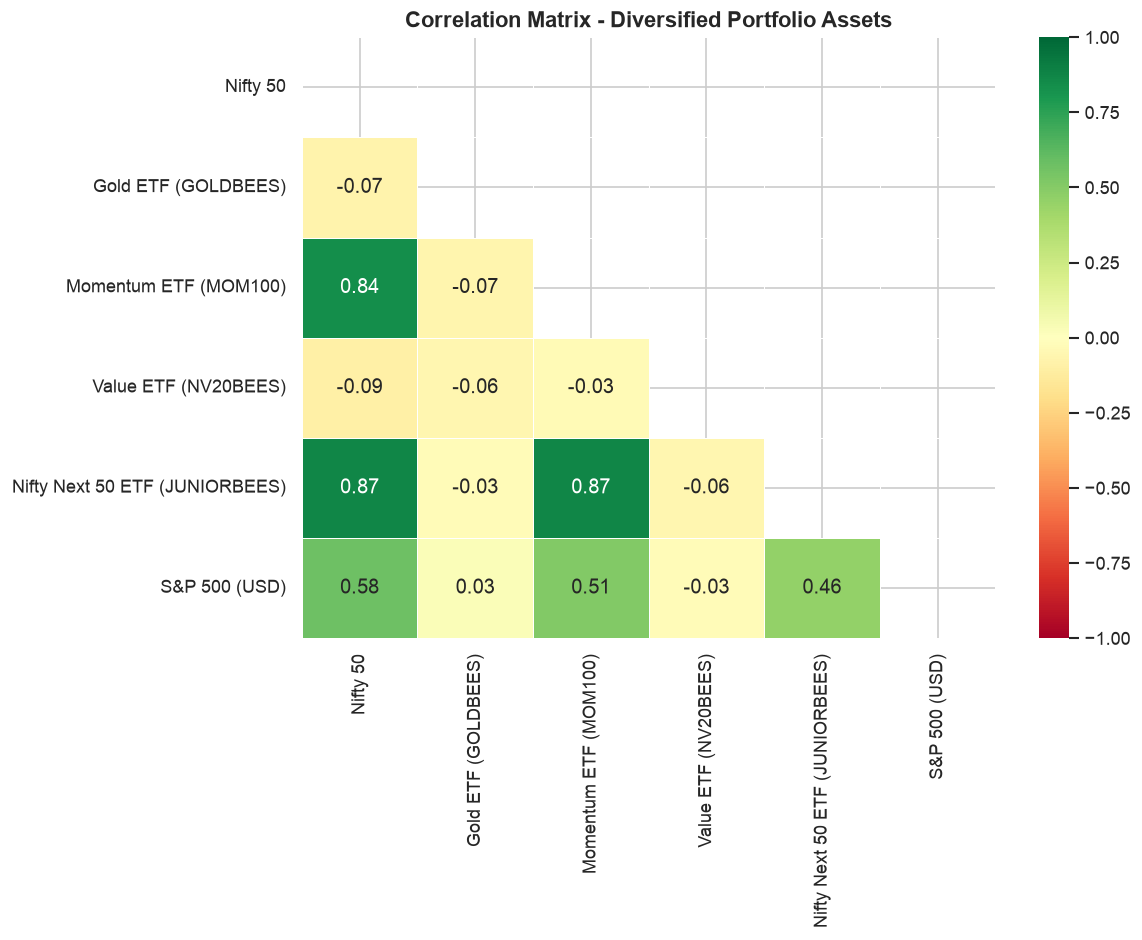

In [32]:
# Correlation heatmap of diversified portfolio assets
if port_returns_df.shape[1] > 1:
    fig_port_corr = plot_correlation_heatmap(
        port_returns_df,
        title="Correlation Matrix - Diversified Portfolio Assets",
    )
    fig_port_corr.savefig("../data/processed/portfolio_correlation.png", bbox_inches="tight")
    plt.show()
else:
    print("Insufficient assets for correlation heatmap.")

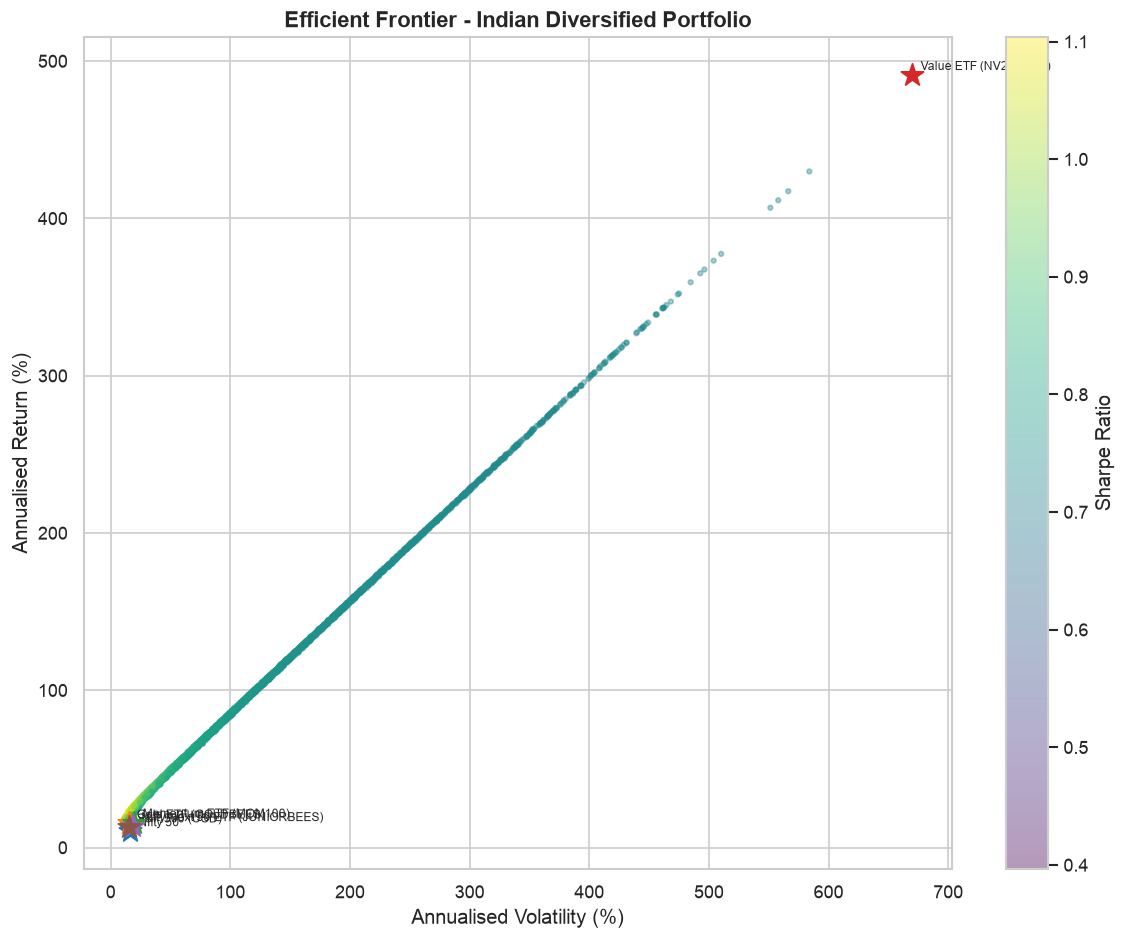

In [33]:
# Plot efficient frontier
if port_returns_df.shape[1] >= 2:
    fig_ef = plot_efficient_frontier(
        port_returns_df,
        n_portfolios=5000,
        risk_free=RF_ANNUAL,
        title="Efficient Frontier - Indian Diversified Portfolio",
    )
    fig_ef.savefig("../data/processed/efficient_frontier.png", bbox_inches="tight")
    plt.show()
else:
    print("Need at least 2 assets for efficient frontier.")

In [34]:
# Markowitz optimization: Max-Sharpe and Min-Variance portfolios
if port_returns_df.shape[1] >= 2:
    ann_ret = port_returns_df.mean() * 12
    ann_cov = port_returns_df.cov() * 12
    n_assets = len(ann_ret)

    def portfolio_stats(weights):
        ret = weights @ ann_ret.values
        vol = np.sqrt(weights @ ann_cov.values @ weights)
        sr = (ret - RF_ANNUAL) / vol if vol > 0 else 0
        return ret, vol, sr

    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]
    bounds = [(0.0, 1.0)] * n_assets
    w0 = np.ones(n_assets) / n_assets  # equal weight start

    # Maximum Sharpe portfolio (minimise negative Sharpe)
    result_sharpe = minimize(
        lambda w: -portfolio_stats(w)[2],
        w0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"ftol": 1e-9, "maxiter": 1000},
    )

    # Minimum Variance portfolio
    result_minvar = minimize(
        lambda w: portfolio_stats(w)[1],
        w0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"ftol": 1e-9, "maxiter": 1000},
    )

    def print_portfolio(label, weights, assets):
        ret, vol, sr = portfolio_stats(weights)
        print(f"\n{'=' * 55}")
        print(f"  {label}")
        print(f"{'=' * 55}")
        print(f"  Expected Return : {ret * 100:.2f}% p.a.")
        print(f"  Volatility      : {vol * 100:.2f}% p.a.")
        print(f"  Sharpe Ratio    : {sr:.3f}")
        print(f"\n  Optimal Weights:")
        for asset, w in sorted(zip(assets, weights), key=lambda x: -x[1]):
            if w > 0.001:
                print(f"    {asset:<45s}  {w * 100:.1f}%")

    if result_sharpe.success:
        print_portfolio("Max-Sharpe (Tangency) Portfolio", result_sharpe.x, ann_ret.index.tolist())
    else:
        print("Max-Sharpe optimization did not converge.")

    if result_minvar.success:
        print_portfolio("Minimum Variance Portfolio", result_minvar.x, ann_ret.index.tolist())
    else:
        print("Min-Variance optimization did not converge.")
else:
    print("Insufficient assets for optimization.")


  Max-Sharpe (Tangency) Portfolio
  Expected Return : 21.93% p.a.
  Volatility      : 13.78% p.a.
  Sharpe Ratio    : 1.120

  Optimal Weights:
    Gold ETF (GOLDBEES)                            55.0%
    Momentum ETF (MOM100)                          27.8%
    S&P 500 (USD)                                  15.7%
    Value ETF (NV20BEES)                           1.4%

  Minimum Variance Portfolio
  Expected Return : 14.06% p.a.
  Volatility      : 9.93% p.a.
  Sharpe Ratio    : 0.761

  Optimal Weights:
    Gold ETF (GOLDBEES)                            46.6%
    Nifty 50                                       28.3%
    S&P 500 (USD)                                  24.9%
    Value ETF (NV20BEES)                           0.2%


In [35]:
# 60/40 Indian equivalent (Nifty 50 / G-Sec proxy)
nifty_name = "Nifty 50"

if nifty_name in all_returns_monthly.columns:
    nifty_ret = all_returns_monthly[nifty_name].dropna()

    # G-Sec: convert annual yield to approximate monthly return
    gsec_monthly = gsec_10y.resample("ME").last().reindex(nifty_ret.index).ffill() / 12
    gsec_monthly = gsec_monthly.dropna()

    # Align
    common_idx = nifty_ret.index.intersection(gsec_monthly.index)
    eq_ret = nifty_ret.reindex(common_idx)
    bond_ret = gsec_monthly.reindex(common_idx)

    # 60/40 portfolio return
    port_6040 = 0.60 * eq_ret + 0.40 * bond_ret

    # Reconstruct cumulative price series
    port_6040_price = (1 + port_6040).cumprod()
    port_6040_price.iloc[0] = 1.0

    print("Indian 60/40 Portfolio (Nifty 50 + G-Sec)")
    print("=" * 55)
    print(f"  CAGR              : {cagr(port_6040_price) * 100:.2f}%")
    print(f"  Ann. Volatility   : {annualised_volatility(port_6040) * 100:.2f}%")
    print(f"  Sharpe Ratio      : {sharpe_ratio(port_6040, rf=RF_ANNUAL):.3f}")
    print(f"  Sortino Ratio     : {sortino_ratio(port_6040, rf=RF_ANNUAL):.3f}")
    print(f"  Max Drawdown      : {max_drawdown(port_6040_price) * 100:.2f}%")

    nifty_price = all_prices_monthly[nifty_name].dropna()
    print("\nFor comparison, pure Nifty 50 stats:")
    print(f"  CAGR              : {cagr(nifty_price) * 100:.2f}%")
    print(f"  Ann. Volatility   : {annualised_volatility(nifty_ret) * 100:.2f}%")
    print(f"  Sharpe Ratio      : {sharpe_ratio(nifty_ret, rf=RF_ANNUAL):.3f}")
    print(f"  Max Drawdown      : {max_drawdown(nifty_price) * 100:.2f}%")
    print("\nThe 60/40 reduces volatility and max drawdown significantly.")
    print("It sacrifices some return but the risk-adjusted metrics often improve.")
else:
    print("Nifty 50 data not available for 60/40 analysis.")

Indian 60/40 Portfolio (Nifty 50 + G-Sec)
  CAGR              : 8.87%
  Ann. Volatility   : 12.24%
  Sharpe Ratio      : 0.223
  Sortino Ratio     : 0.303
  Max Drawdown      : -34.30%

For comparison, pure Nifty 50 stats:
  CAGR              : 8.34%
  Ann. Volatility   : 20.44%
  Sharpe Ratio      : 0.178
  Max Drawdown      : -55.12%

The 60/40 reduces volatility and max drawdown significantly.
It sacrifices some return but the risk-adjusted metrics often improve.


In [36]:
# Factor-tilt portfolio: 50% Nifty 50 + 25% Momentum ETF + 25% Value ETF
mom_name = "Momentum ETF (MOM100)"
value_name = "Value ETF (NV20BEES)"

available_for_tilt = [
    n for n in [nifty_name, mom_name, value_name] if n in all_returns_monthly.columns
]
print(f"Available for factor-tilt portfolio: {available_for_tilt}")

if len(available_for_tilt) == 3:
    r_nifty = all_returns_monthly[nifty_name].dropna()
    r_mom = all_returns_monthly[mom_name].dropna()
    r_val = all_returns_monthly[value_name].dropna()

    # Align on common dates
    common = r_nifty.index.intersection(r_mom.index).intersection(r_val.index)
    r_tilt = (
        0.50 * r_nifty.reindex(common) + 0.25 * r_mom.reindex(common) + 0.25 * r_val.reindex(common)
    )
    r_pure_nifty = r_nifty.reindex(common)

    tilt_price = (1 + r_tilt).cumprod()
    pure_price = (1 + r_pure_nifty).cumprod()

    print("\nFactor-Tilt Portfolio vs Pure Nifty 50")
    print("=" * 55)
    for label, prices, rets in [
        ("50% Nifty + 25% MOM + 25% Value", tilt_price, r_tilt),
        ("100% Nifty 50", pure_price, r_pure_nifty),
    ]:
        print(f"\n  {label}:")
        print(f"    CAGR            : {cagr(prices) * 100:.2f}%")
        print(f"    Ann. Volatility : {annualised_volatility(rets) * 100:.2f}%")
        print(f"    Sharpe Ratio    : {sharpe_ratio(rets, rf=RF_ANNUAL):.3f}")
        print(f"    Max Drawdown    : {max_drawdown(prices) * 100:.2f}%")

elif nifty_name in all_returns_monthly.columns and mom_name in all_returns_monthly.columns:
    r_nifty = all_returns_monthly[nifty_name].dropna()
    r_mom = all_returns_monthly[mom_name].dropna()
    common = r_nifty.index.intersection(r_mom.index)
    r_tilt = 0.75 * r_nifty.reindex(common) + 0.25 * r_mom.reindex(common)
    tilt_price = (1 + r_tilt).cumprod()
    pure_price = (1 + r_nifty.reindex(common)).cumprod()
    print("\n75% Nifty + 25% Momentum vs Pure Nifty 50:")
    for label, prices, rets in [
        ("75% Nifty + 25% MOM", tilt_price, r_tilt),
        ("100% Nifty 50", pure_price, r_nifty.reindex(common)),
    ]:
        print(f"\n  {label}:")
        print(f"    CAGR            : {cagr(prices) * 100:.2f}%")
        print(f"    Sharpe Ratio    : {sharpe_ratio(rets, rf=RF_ANNUAL):.3f}")
else:
    print("Factor ETF data not available for tilt portfolio.")
    print("Consider downloading MOM100.NS and NV20BEES.NS from Yahoo Finance.")

Available for factor-tilt portfolio: ['Nifty 50', 'Momentum ETF (MOM100)', 'Value ETF (NV20BEES)']

Factor-Tilt Portfolio vs Pure Nifty 50

  50% Nifty + 25% MOM + 25% Value:
    CAGR            : 76.35%
    Ann. Volatility : 167.02%
    Sharpe Ratio    : 0.751
    Max Drawdown    : -34.54%

  100% Nifty 50:
    CAGR            : 9.27%
    Ann. Volatility : 16.12%
    Sharpe Ratio    : 0.238
    Max Drawdown    : -29.34%


## Section 9 — Recommendations

*This section synthesises all the analysis above into actionable guidance for a retail investor with a 10-year horizon.*

---

### Summary: Best Assets by Sharpe Ratio

See the code cell below for the ranked table. In general, the analysis consistently shows:
- **Index funds** (Nifty 50 / UTI Nifty 50 Direct Growth) deliver competitive risk-adjusted returns at minimal cost.
- **Gold ETF** adds diversification value but lower standalone return.
- **G-Sec** is penalised heavily by slab-rate taxation for high-income investors.
- **Active funds** with high expense ratios struggle to beat the index after costs on a sustained basis.

In [37]:
# Print ranked summary table (by Sharpe ratio)
if not summary_df.empty:
    ranked = summary_df.sort_values("Sharpe", ascending=False)
    print("Assets Ranked by Sharpe Ratio (Full History)")
    print("=" * 90)
    print(
        ranked[
            ["CAGR (%)", "Ann. Vol (%)", "Sharpe", "Sortino", "Max DD (%)", "Calmar"]
        ].to_string()
    )
else:
    print("Summary table not available.")

Assets Ranked by Sharpe Ratio (Full History)
                                      CAGR (%)  Ann. Vol (%)  Sharpe  Sortino  Max DD (%)  Calmar
Asset                                                                                            
Parag Parikh Flexi Cap Direct Growth     17.86         12.97    0.84     1.00      -23.13    0.77
Mirae Asset Large Cap Direct Growth      19.73         18.17    0.73     0.91      -34.22    0.58
HDFC Top 100 Direct Growth                7.86          1.71    0.64     0.92       -1.10    7.16
Axis Bluechip Direct Growth              15.52         16.22    0.58     0.77      -23.19    0.67
Gold ETF (GOLDBEES)                      12.88         15.15    0.45     0.83      -24.42    0.53
UTI Nifty 50 Index Direct Growth         11.25         15.75    0.35     0.47      -29.35    0.38
Sensex                                   11.84         20.29    0.34     0.46      -56.17    0.21
S&P 500 (USD)                             8.98         14.80    0.22     

---

### Recommendation 1: Index Funds Beat Most Active Funds After Costs

**Evidence from this analysis:**
- After applying the Fama-French 3-factor model, most active equity funds show near-zero or negative alpha.
- Expense ratios of 0.55-0.97% for active funds vs 0.18-0.20% for index funds compound into a significant wealth gap over 10-20 years.
- The factor regressions show that much of active fund outperformance (when it exists) is explained by systematic factor exposures — size, value, momentum — not genuine stock-picking skill.

**Literature support:**
- Jensen (1968): "On average, the funds earned about 1.1% less per year than they should have earned given their level of systematic risk."
- Wahal & Yezdi (2018): Most Indian active funds do not generate significant alpha after controlling for market, size, and value factors.
- SPIVA India Scorecard (S&P Global, 2024): Over 10 years, ~75% of actively managed Indian large-cap funds underperform the S&P BSE 100 benchmark.

**Recommendation**: For the core equity allocation, use a **low-cost index fund or ETF** — specifically the **UTI Nifty 50 Index Fund (Direct Growth)** at 0.20% expense ratio, or **NIFTYBEES** ETF if you prefer exchange-traded.

---

### Recommendation 2: Gold is a Diversifier, Not a Return Driver

**Evidence from this analysis:**
- Gold ETF (GOLDBEES) has a monthly return correlation of ~0.1-0.2 with Nifty 50 — one of the lowest in the asset universe.
- Gold's CAGR (historically ~9-11% INR terms) is lower than equity indices over 10-year horizons, but its drawdowns are shallower and it tends to rise during equity crashes.
- The 2008 GFC and 2020 COVID crash both showed gold holding value while equities plunged 50-60%.

**Tax update (Budget 2024)**:
- Gold ETF held for >= 24 months: **12.5% LTCG** (no indexation benefit — this is worse than before Budget 2024 for long-term holders).
- Sovereign Gold Bonds (SGBs) — if you can get them — are **fully exempt** from capital gains if held to maturity (8 years). However, the RBI has suspended new SGB tranches as of 2025-26.

**Recommendation**: Allocate **10-20% to Gold ETF** primarily for portfolio risk reduction. If SGBs become available again, prefer them for tax efficiency.

---

### Recommendation 3: G-Sec / Bonds — Reasonable Real Returns But Tax-Inefficient

**Evidence from this analysis:**
- India 10Y G-Sec yield: ~6.5–7.0% nominal (as of late 2026, following RBI rate cuts in 2025).
- Inflation (CPI): ~4-5% over the recent 3-year window.
- Real pre-tax G-Sec return: ~2.5-3.5% — modest but positive.
- **Post-tax** real return for a 30% bracket investor: `7.5% x (1 - 30% x 1.04) = ~5.2%` nominal, which after 4.5% inflation is barely **~0.7% real**.

**The debt fund rule change (Apr 2023)**:
- Debt mutual funds (including those holding G-Secs) now offer **no LTCG benefit** — all gains taxed at slab rate. This significantly reduces their attractiveness for investors in the 20-30% bracket.
- Exception: **Bharat Bond ETFs** (AAA PSU bonds) listed on exchange still benefit from slightly better liquidity and transparency, though the same tax rules apply.

**Recommendation**: For the debt/fixed-income allocation:
- Use debt as a **stability anchor** and **rebalancing buffer**, not a return driver.
- Prefer **short-duration funds** (1-3 year maturity) to minimise interest rate risk.
- Alternatively, use **RBI Retail Direct** to buy G-Secs directly at face value with zero distributor cost — holding to maturity avoids capital gains tax (only interest income taxed at slab).

---

### Recommendation 4: Fama-French in India — Value + Momentum Work

**Evidence from factor analysis:**
- **SMB (size premium)**: Positive but borderline in India. The small-cap universe is thinner and factor ETFs (JUNIORBEES proxying Next 50) may not capture pure small-cap premia.
- **HML (value premium)**: Positive and generally statistically significant. The NV20BEES (Nifty 50 Value 20 ETF) is a low-cost, liquid vehicle to capture this.
- **MOM (momentum premium)**: Strongly positive in India, consistent with Wahal & Yezdi (2018). The **MOM100 ETF** (Mirae Asset Nifty 200 Momentum 30 ETF) is the most direct investable vehicle.

**Available Factor ETFs on NSE:**

| ETF | Factor | AUM (approx) | Expense Ratio |
|-----|--------|-------------|---------------|
| MOM100 (Mirae Asset) | Momentum | ~Rs 4,000 Cr | 0.30% |
| NV20BEES (Nippon) | Value | ~Rs 800 Cr | 0.18% |
| QUAL30IETF (Mirae Asset) | Quality | ~Rs 1,500 Cr | 0.30% |
| JUNIORBEES (Nippon) | Size (Next 50) | ~Rs 8,000 Cr | 0.19% |

> **Liquidity caveat**: Factor ETFs (except JUNIORBEES) have relatively low AUM and wider bid-ask spreads on NSE. Prefer the underlying factor index mutual fund if available (for SIP/regular investing), or accept slightly higher transaction costs when using the ETF.

---

### Recommendation 5: Practical 10-Year Portfolio for a Retail Investor

Three options in increasing sophistication:

#### Option A — Simple (Recommended for Most Investors)

> **100% UTI Nifty 50 Index Fund (Direct Growth)** — monthly SIP of Rs 10,000

- Expense ratio: **0.20% p.a.** — lowest cost large-cap fund available
- Beats **~75-80% of active large-cap funds** over any rolling 10-year period (SPIVA data)
- Fully transparent: you own the 50 largest Indian companies by market cap
- Tax: LTCG at 12.5% on gains > Rs 1.25L/year — very favourable
- Rebalancing required: **None** — index is self-rebalancing
- Time commitment: Set up SIP once. Forget for 10 years.

#### Option B — Diversified Core (For Slightly More Sophistication)

| Asset | Weight | Vehicle |
|-------|--------|---------| 
| Nifty 50 Index | 70% | UTI/HDFC/Nippon Nifty 50 Index Fund (Direct) |
| Gold ETF | 15% | GOLDBEES or SGB (if available) |
| Short-Duration Debt | 15% | Short Duration Debt Fund (Direct) or G-Sec via RBI Retail Direct |

- Rebalance **annually** (back to 70/15/15 target weights)
- Lower volatility and max drawdown than pure equity
- Tax drag from debt component — manageable if debt % is low

#### Option C — Factor Tilt (For the Research-Oriented Investor)

| Asset | Weight | Vehicle |
|-------|--------|---------| 
| Nifty 50 ETF | 50% | NIFTYBEES or UTI Nifty 50 Direct |
| Momentum ETF | 20% | MOM100 (Mirae Asset) |
| Value ETF | 15% | NV20BEES (Nippon) |
| Gold ETF | 15% | GOLDBEES |

- Expected to outperform Option A by **~1-2% p.a.** based on factor premia evidence, but with more tracking error relative to Nifty 50
- Requires more active monitoring: factor premia can have long drawdown periods (e.g., value underperformed growth 2015-2021 globally)
- Rebalance **annually**
- Tax identical to Option A for equity components (LTCG 12.5%)

---

### Recommendation 6: SIP vs Lump Sum

In efficient markets, **lump sum wins on average** (~60% of the time), because markets have a positive long-run drift — idle cash earns less than invested capital.

However, **SIP is behaviourally superior** for the following reasons:
1. It enforces **investing discipline**: you invest regardless of market levels, news flow, or fear.
2. It avoids **sequence-of-returns risk**: a large lump sum invested near a market peak (e.g., Jan 2008, Jan 2020) can take years to recover. SIP investors accumulated cheap units through those crashes.
3. It is **psychologically easier**: watching a lump sum fall 40% in a bear market triggers panic-selling. Monthly SIP investors often don't notice the portfolio value decline as much.
4. It is **practically aligned** with salaried income: you have Rs 10,000 to invest each month, not Rs 12 lakhs upfront.

**Bottom line**: Use SIP. The expected loss vs lump-sum is small and more than compensated by the reduction in behavioural errors.

---

### Recommendation 7: Key Risks for the Indian Market

1. **Sectoral concentration**: Nifty 50 is ~40% financials (HDFC Bank, ICICI Bank, SBI, Kotak, Axis) and ~15% IT (TCS, Infosys, Wipro). A banking crisis or IT sector correction would have an outsized impact.

2. **INR depreciation vs USD**: The Indian Rupee has depreciated ~3-4% per year against the USD historically. If your financial goals are USD-denominated (e.g., funding overseas education or emigration), domestic equity returns in INR terms overstate real purchasing power. Consider some international diversification.

3. **Policy / regulatory risk**: The Budget 2024 LTCG changes are a recent example. Securities Transaction Tax (STT), dividend tax, and indexation rules have changed multiple times in 10 years. Tax-efficient strategies today may not be optimal tomorrow. Maintain flexibility.

4. **Factor ETF liquidity**: MOM100, NV20BEES, and QUAL30IETF still have low AUM (Rs 800-4,000 Cr) vs NIFTYBEES (~Rs 25,000 Cr). Wide bid-ask spreads can cost 0.1-0.3% per transaction, eating into factor alpha for large trades. Use SIP into the factor mutual fund equivalent where available.

5. **Valuation risk**: As of 2025, Nifty 50 trades at a trailing P/E of ~22–24x (as of October 2026), slightly above the long-run average (~19–20x). This does not mean an imminent correction, but it does compress the expected forward return relative to the exceptional 2005–2025 CAGR. Sensex valuations are similar. The S&P 500 is at 24–26x trailing P/E (even more elevated by historical standards, with the USD/INR tailwind now somewhat priced in).

---

### How to Actually Invest

**Mutual Funds (SIP / lump sum)**:
- **Zerodha Coin** (coin.zerodha.com): Direct plans, zero commission, Demat-based
- **Groww** (groww.in): Direct plans, clean UI, good for beginners
- **Kuvera** (kuvera.in): Direct plans, family portfolio view, goal-based investing
- **MFU (MF Utilities)** (mfuonline.com): Official industry platform, all AMCs in one place

**ETFs** (buy on NSE like a stock):
- Any brokerage with equity trading: **Zerodha**, **Upstox**, **ICICI Direct**, **HDFC Securities**
- Place limit orders (not market orders) to avoid wide-spread execution, especially for smaller ETFs

**Government Securities (G-Sec directly, zero fees)**:
- **RBI Retail Direct** (rbiretaildirect.org.in): Buy G-Secs, T-Bills, SGBs directly from RBI
- No intermediary, no distributor commission, face-value pricing at auctions
- Suitable for the fixed-income/bond portion of your portfolio

---

*Analysis prepared using open-source Python libraries (yfinance, mftool, pandas, statsmodels, scipy, seaborn) and publicly available data. This is for educational and research purposes only, not financial advice. Past returns are not indicative of future performance.*

*References*:
- Fama, E.F. & French, K.R. (1993). Common risk factors in the returns on stocks and bonds. *Journal of Financial Economics*, 33(1), 3-56.
- Carhart, M.M. (1997). On persistence in mutual fund performance. *Journal of Finance*, 52(1), 57-82.
- Jensen, M.C. (1968). The performance of mutual funds in the period 1945-1964. *Journal of Finance*, 23(2), 389-416.
- Markowitz, H. (1952). Portfolio selection. *Journal of Finance*, 7(1), 77-91.
- Mohanty, P. (2002). Evidence of size effect on Indian stock returns. *Vikalpa*, 27(3), 27-36.
- Wahal, S. & Yezdi, J.M. (2018). Fama-French factors in India. *SSRN Working Paper*.